In [2]:
!pip install -q imbalanced-learn flask wordcloud networkx gensim pyLDAvis

 imports


In [3]:

import os
import re
import sys
import time
import string
import pickle
import zipfile
import warnings
import subprocess
import unicodedata
import collections


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from wordcloud import WordCloud
from IPython.display import display


import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.probability import FreqDist
from nltk.cluster.util import cosine_distance


from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)


from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


import gensim
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel
import pyLDAvis
import pyLDAvis.gensim_models
from scipy.spatial.distance import jensenshannon


for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4',
                 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(resource, quiet=True)

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)
print("All libraries loaded  |  gensim", gensim.__version__, " |  pyLDAvis", pyLDAvis.__version__)

All libraries loaded  |  gensim 4.4.0  |  pyLDAvis 3.4.0


data files


In [4]:
def find_data_file(extension, keyword, uploaded_names):

    matches = [n for n in uploaded_names if n.lower().endswith(extension)]
    preferred = [n for n in matches if keyword in n.lower()]
    if preferred or matches:
        return (preferred or matches)[0]

    for folder in ['.', 'data', '../data']:
        if os.path.isdir(folder):
            local = sorted(n for n in os.listdir(folder) if n.lower().endswith(extension))
            preferred = [n for n in local if keyword in n.lower()]
            if preferred or local:
                return os.path.join(folder, (preferred or local)[0])
    raise FileNotFoundError(f"No {extension} file found. Re-run this cell and select BOTH "
                            f"research_abstracts.json and research_corpus.zip.")

try:
    from google.colab import files
    print("Select BOTH research_abstracts.json and research_corpus.zip (Ctrl/Cmd + click)")
    uploaded_names = list(files.upload().keys())
except ImportError:
    uploaded_names = []

abstracts_path = find_data_file('.json', 'abstract', uploaded_names)
corpus_zip_path = find_data_file('.zip', 'corpus', uploaded_names)
print("Abstracts dataset (Q1, Q2):", abstracts_path)
print("Research corpus   (Q3, Q4):", corpus_zip_path)

Select BOTH research_abstracts.json and research_corpus.zip (Ctrl/Cmd + click)


Saving research_corpus.zip to research_corpus (1).zip
Saving research_abstracts.json to research_abstracts (1).json
Abstracts dataset (Q1, Q2): research_abstracts (1).json
Research corpus   (Q3, Q4): research_corpus (1).zip



# Question 1

## 1.1

In [5]:
df = pd.read_json(abstracts_path)
print("Shape:", df.shape)
df.head()

Shape: (1138, 3)


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation rate could help the central bank and other government departments to be...,ai
1,10.1007/s43546-022-00384-2,"Our study examined the disaggregation of inflation components in Nigeria using the stacked ensemble approach, a mach...",ai
2,10.1002/for.2667,This paper develops a dynamic factor model that uses euro area country-specific information on output and inflation ...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model to examine Japan’s soft lockdown policies in 2021 under the COVID-19 c...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifying conditions under which individual stakeholders in a collective actio...,classical


I First looked at the data i am given, becuase before cleaning anything I want to know what I'm dealing with: the column types, missing values, duplicates and how the labels are spread out.

In [6]:
df.info()
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate abstracts:", df.duplicated(subset='Abstract').sum())
print("\nLabel distribution:\n", df['Label'].value_counts())
print("\nWords per abstract:\n", df['Abstract'].str.split().str.len().describe().round(1))

<class 'pandas.core.frame.DataFrame'>
Index: 1138 entries, 0 to 1137
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DOI       1134 non-null   object
 1   Abstract  1138 non-null   object
 2   Label     1138 non-null   object
dtypes: object(3)
memory usage: 35.6+ KB

Missing values per column:
 DOI         4
Abstract    0
Label       0
dtype: int64

Duplicate abstracts: 13

Label distribution:
 Label
classical    900
ai           238
Name: count, dtype: int64

Words per abstract:
 count    1138.0
mean      171.3
std       103.6
min        16.0
25%       116.0
50%       152.0
75%       200.8
max      2075.0
Name: Abstract, dtype: float64


Reading through a few of the abstracts, the "noise" in this dataset is mostly publisher and formatting leftovers rather than HTML:



In [7]:
noise_patterns = {
    'copyright notice': r'©',
    'URL / web link': r'http\S+|www\.\S+',
    'bracketed text': r'\[[^\]]*\]',
    'heading at start': r'^\s*(?:Abstract|ABSTRACT|Background)',
    'non-ASCII characters': r'[^\x00-\x7F]',
    'digits': r'\d',
}
for name, pattern in noise_patterns.items():
    print(f"{name:22s}: {df['Abstract'].str.contains(pattern, regex=True).sum()} abstracts")

print("\nExample:", df.loc[df['Abstract'].str.contains('©'), 'Abstract'].iloc[0][-120:])

copyright notice      : 16 abstracts
URL / web link        : 7 abstracts
bracketed text        : 19 abstracts
heading at start      : 39 abstracts
non-ASCII characters  : 443 abstracts
digits                : 689 abstracts

Example: performance is consistent across subsamples and a number of inflation measures. Copyright © 2008 John Wiley & Sons, Ltd.


#### Removing duplicates and empty rows


In [8]:
df = df.drop_duplicates(subset='Abstract').reset_index(drop=True)
df = df[df['Abstract'].str.strip() != ''].reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1125, 3)


Step 1 removes the 13 duplicate abstracts, so no abstract lands in both the training and the test set. The denoise_text function then applies regular expressions with re.sub (Cuantum Technologies, 2024, section 2.3). The function strips the copyright notice and the bracketed text first, so publisher words such as wiley never reach the token list.


In [9]:
def denoise_text(text):

    text = re.sub(r'(copyright\s*)?©.*$', ' ', text, flags=re.IGNORECASE)

    text = re.sub(r'http\S+|www\.\S+', ' ', text)

    text = re.sub(r'\[[^\]]*\]', ' ', text)
    text = re.sub(r'^\s*(abstract|background)\s*[.:]?', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'[‐-―−]', ' ', text)
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('ascii')
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['denoised'] = df['Abstract'].apply(denoise_text)

Step 2 follows the preprocess_text function from the textbook (Cuantum Technologies, 2024, section 13.2). The function lowercases the text, splits the text into tokens, drops stop words and short tokens, and reduces each word to the dictionary form with the WordNet lemmatizer (Cuantum Technologies, 2024, sections 2.2 and 2.4). The stop word list also holds academic words such as paper, study and result, because every abstract uses them whatever the topic.


In [10]:
lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words('english'))
academic_stop_words = {
    'paper', 'study', 'article', 'research', 'result', 'results', 'method', 'methods',
    'conclusion', 'conclusions', 'objective', 'background', 'finding', 'findings',
    'propose', 'proposed', 'show', 'shows', 'also', 'however', 'using', 'use', 'used',
    'based', 'approach', 'author', 'authors', 'within', 'among', 'may', 'well', 'one', 'two'
}
stop_words = stop_words.union(academic_stop_words)

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()
    # Tokenize text
    tokens = nltk.word_tokenize(text)
    # Remove punctuation, stop words and very short tokens
    tokens = [word for word in tokens
              if word not in string.punctuation and word not in stop_words and len(word) > 2]
    # Lemmatize tokens
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    # A second stop word pass catches plurals that only become stop words after lemmatizing
    tokens = [word for word in tokens if word not in stop_words]
    return ' '.join(tokens)

df['clean_text'] = df['denoised'].apply(preprocess_text)

### Checking the result

In [11]:
example = df.loc[df['Abstract'].str.contains('©')].index[0]
print("ORIGINAL:\n", df.loc[example, 'Abstract'][-300:])
print("\nCLEANED:\n", df.loc[example, 'clean_text'][-200:])

before = df['Abstract'].str.split().str.len().sum()
after = df['clean_text'].str.split().str.len().sum()
print(f"\nTotal words before: {before:,}")
print(f"Total words after:  {after:,}  ({(1 - after / before) * 100:.1f}% of the tokens removed as noise)")
print("Empty abstracts after cleaning:", (df['clean_text'].str.len() == 0).sum())

ORIGINAL:
 n model averaging for pseudo out‐of‐sample prediction of US inflation, and find that it generally gives more accurate forecasts than simple equal‐weighted averaging. This superior performance is consistent across subsamples and a number of inflation measures. Copyright © 2008 John Wiley & Sons, Ltd.

CLEANED:
 sian model averaging pseudo sample prediction inflation find generally give accurate forecast simple equal weighted averaging superior performance consistent across subsamples number inflation measure

Total words before: 193,044
Total words after:  110,454  (42.8% of the tokens removed as noise)
Empty abstracts after cleaning: 0


Just over 40% of all tokens turn out to be noise, mostly stop words, numbers and punctuation. What's left is the topic vocabulary, which is what the classifier should learn from.

## 1.2

In [12]:
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'unique values': df.nunique(),
    'unique ratio': (df.nunique() / len(df)).round(3),
    'missing': df.isnull().sum()
}).loc[['DOI', 'Abstract', 'Label']]
summary

,dtype,unique values,unique ratio,missing
DOI,object,1123,0.998,2
Abstract,object,1125,1.000,0
Label,object,2,0.002,0


The table drives the choice. DOI has a unique ratio close to 1 and holds missing values. A DOI identifies a paper but says nothing about the content, so the model drops the column. Abstract holds the only text about the topic of each paper, so the cleaned abstract becomes the input feature. Label holds the two classes, classical and ai, so the model treats Label as the target and encodes the classes as 0 and 1.

In [13]:
df['target'] = df['Label'].map({'classical': 0, 'ai': 1})
data = df[['clean_text', 'target']]
print(data['target'].value_counts())
print(f"\nShare of 'ai' papers: {data['target'].mean():.1%}  ->  the classes are imbalanced")

target
0    890
1    235
Name: count, dtype: int64

Share of 'ai' papers: 20.9%  ->  the classes are imbalanced


 Feature modelling: here i decided to use **Bag of Words** (`CountVectorizer`) and **TF-IDF** (`TfidfVectorizer`) for turning the abstract into numbers


## 1.3 Baseline model and performance report

Before training the baseline, the next cell compares the two feature sets with 5-fold cross-validation and Multinomial Naive Bayes. The score is F1 for the AI class, because 79% of the abstracts are classical and accuracy hides errors on the small class.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, vec in [('Bag of Words', CountVectorizer(min_df=2, ngram_range=(1, 2))),
                  ('TF-IDF', TfidfVectorizer(min_df=2, ngram_range=(1, 2)))]:
    pipe = Pipeline([('vectorizer', vec), ('classifier', MultinomialNB())])
    f1 = cross_val_score(pipe, data['clean_text'], data['target'], cv=cv, scoring='f1')
    print(f"{name:13s} F1 (ai): {f1.mean():.3f}")

Bag of Words  F1 (ai): 0.765
TF-IDF        F1 (ai): 0.125


In [15]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    data['clean_text'], data['target'], test_size=0.2, random_state=42, stratify=data['target'])

vectorizer = CountVectorizer(min_df=2, ngram_range=(1, 2))
X_train = vectorizer.fit_transform(X_train_text)     # fit only on training data
X_test = vectorizer.transform(X_test_text)

print("Training set:", X_train.shape, " Test set:", X_test.shape)

Training set: (900, 12905)  Test set: (225, 12905)


Bag of Words wins with an F1 of 0.765 against 0.125 for TF-IDF. TF-IDF turns each abstract into small fractions, so the Naive Bayes word probabilities flatten and the 79% classical prior decides almost every prediction. The baseline therefore uses Bag of Words with Multinomial Naive Bayes, the pairing in the textbook classification example (Cuantum Technologies, 2024, section 3.1.4). The split keeps 80% of the abstracts for training and 20% for testing, and stratify holds the class ratio equal in both sets.

In [16]:
classifier = MultinomialNB()
classifier.fit(X_train, y_train)

y_train_pred = classifier.predict(X_train)
y_test_pred = classifier.predict(X_test)

print(f"Training accuracy: {accuracy_score(y_train, y_train_pred):.3f}")
print(f"Test accuracy:     {accuracy_score(y_test, y_test_pred):.3f}")
print(f"Accuracy if I just predicted 'classical' every time: {(y_test == 0).mean():.3f}")

Training accuracy: 0.978
Test accuracy:     0.889
Accuracy if I just predicted 'classical' every time: 0.791


### Model learning: performance on the data it was trained on

In [17]:
print(classification_report(y_train, y_train_pred, target_names=['classical', 'ai'], digits=3))

              precision    recall  f1-score   support

   classical      0.991     0.980     0.986       712
          ai      0.929     0.968     0.948       188

    accuracy                          0.978       900
   macro avg      0.960     0.974     0.967       900
weighted avg      0.978     0.978     0.978       900



### Generalisation: performance on unseen test data

              precision    recall  f1-score   support

   classical      0.927     0.933     0.930       178
          ai      0.739     0.723     0.731        47

    accuracy                          0.889       225
   macro avg      0.833     0.828     0.831       225
weighted avg      0.888     0.889     0.888       225



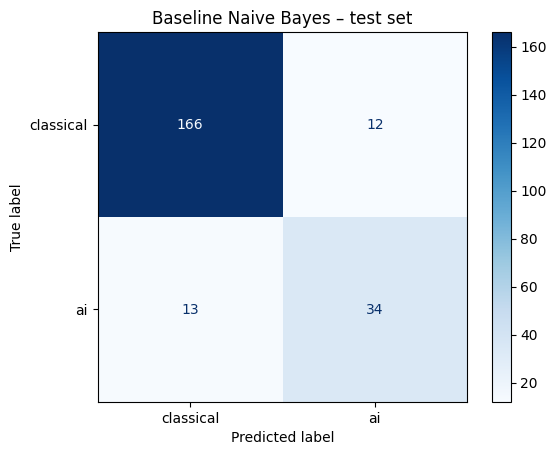

In [18]:
print(classification_report(y_test, y_test_pred, target_names=['classical', 'ai'], digits=3))

cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['classical', 'ai'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Baseline Naive Bayes – test set")
plt.show()

### How stable is it? 5-fold cross-validation


In [19]:
baseline_pipeline = Pipeline([
    ('vectorizer', CountVectorizer(min_df=2, ngram_range=(1, 2))),
    ('classifier', MultinomialNB())
])
for metric in ['accuracy', 'precision', 'recall', 'f1']:
    scores = cross_val_score(baseline_pipeline, data['clean_text'], data['target'], cv=cv, scoring=metric)
    print(f"{metric:10s}: {scores.mean():.3f} ± {scores.std():.3f}   folds: {np.round(scores, 3)}")

accuracy  : 0.906 ± 0.017   folds: [0.902 0.876 0.907 0.924 0.92 ]
precision : 0.804 ± 0.063   folds: [0.791 0.702 0.795 0.895 0.837]
recall    : 0.732 ± 0.022   folds: [0.723 0.702 0.745 0.723 0.766]
f1        : 0.765 ± 0.036   folds: [0.756 0.702 0.769 0.8   0.8  ]


### Learning curve
To see how the model learns as it gets more data, I retrain it on growing portions of the training set and track training vs test accuracy.
A big gap that doesn't close would point to overfitting. Two lines that meet low down would point to underfitting.

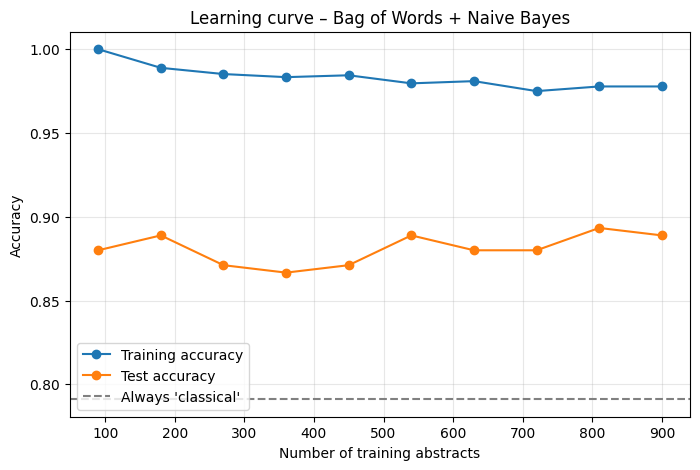

In [20]:
train_sizes = np.linspace(0.1, 1.0, 10)
train_scores, test_scores = [], []

for size in train_sizes:
    n = int(size * len(X_train_text))
    X_part, y_part = X_train_text.iloc[:n], y_train.iloc[:n]
    vec = CountVectorizer(min_df=2, ngram_range=(1, 2))
    model = MultinomialNB().fit(vec.fit_transform(X_part), y_part)
    train_scores.append(accuracy_score(y_part, model.predict(vec.transform(X_part))))
    test_scores.append(accuracy_score(y_test, model.predict(vec.transform(X_test_text))))

plt.figure(figsize=(8, 5))
plt.plot(train_sizes * len(X_train_text), train_scores, 'o-', label='Training accuracy')
plt.plot(train_sizes * len(X_train_text), test_scores, 'o-', label='Test accuracy')
plt.axhline((y_test == 0).mean(), color='grey', linestyle='--', label="Always 'classical'")
plt.xlabel("Number of training abstracts")
plt.ylabel("Accuracy")
plt.title("Learning curve – Bag of Words + Naive Bayes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Comment on the model's performance

The model learns the training data well, with 97.8% training accuracy, so the model does not underfit. Test accuracy reaches 88.9%, and cross-validation confirms the figure at 90.6% ± 1.7%. A model predicting classical for every abstract scores 79.1%, so the baseline adds about 10 points. The gap of 9 points between training and test accuracy shows mild overfitting. The learning curve stays flat as the training set grows, so more data of the same kind adds little.

The weak spot is the AI class, with precision 0.74 and recall 0.72. The model misses 13 of the 47 AI papers in the test set. Both classes share economics words such as inflation, price and forecast, so an AI paper naming the method once loses against the shared vocabulary. For a screening tool, missing 28% of AI papers costs your users relevant work. Question 2 targets this weakness.

### Question 2


## 2.1 Training four machine learning models

 The four models come from two families. Logistic Regression and a Linear Support Vector Machine are the linear text classifiers the textbook recommends (Cuantum Technologies, 2024, section 13.3.1). Random Forest and Gradient Boosting add tree ensembles, which pick up word combinations a linear model misses. All four models read TF-IDF features with single words and two-word phrases, because these models work well with normalised values. scikit-learn supplies all four implementations (Pedregosa et al., 2011).



In [21]:
X, y = df['clean_text'], df['target']
X_train_text, X_test_text, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

results = []

def evaluate_model(name, pipeline, group):
    pipeline.fit(X_train_text, y_train)
    y_train_pred = pipeline.predict(X_train_text)
    y_pred = pipeline.predict(X_test_text)
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=['accuracy', 'f1'], n_jobs=-1)
    row = {
        'model': name,
        'group': group,
        'train acc': accuracy_score(y_train, y_train_pred),
        'test acc': accuracy_score(y_test, y_pred),
        'precision (ai)': precision_score(y_test, y_pred),
        'recall (ai)': recall_score(y_test, y_pred),
        'F1 (ai)': f1_score(y_test, y_pred),
        'CV acc': scores['test_accuracy'].mean(),
        'CV F1 (ai)': scores['test_f1'].mean(),
    }
    results.append(row)
    return pipeline, row

baseline = Pipeline([
    ('vectorizer', CountVectorizer(min_df=2, ngram_range=(1, 2))),
    ('classifier', MultinomialNB())
])
baseline, baseline_row = evaluate_model('Naive Bayes (baseline)', baseline, 'baseline')

In [22]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVM': LinearSVC(max_iter=5000),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

for name, clf in models.items():
    pipeline = Pipeline([
        ('vectorizer', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
        ('classifier', clf)
    ])
    evaluate_model(name, pipeline, '2.1 models')
    print("done:", name)

results_df = pd.DataFrame(results).set_index('model')
results_df.drop(columns='group').round(3)

done: Logistic Regression
done: Linear SVM
done: Random Forest
done: Gradient Boosting


,train acc,test acc,precision (ai),recall (ai),F1 (ai),CV acc,CV F1 (ai)
model,,,,,,,
Naive Bayes (baseline),0.978,0.889,0.739,0.723,0.731,0.906,0.765
Logistic Regression,0.884,0.836,0.917,0.234,0.373,0.853,0.456
Linear SVM,1.000,0.907,0.906,0.617,0.734,0.915,0.758
Random Forest,1.000,0.893,1.000,0.489,0.657,0.908,0.721
Gradient Boosting,0.988,0.893,0.829,0.617,0.707,0.908,0.747


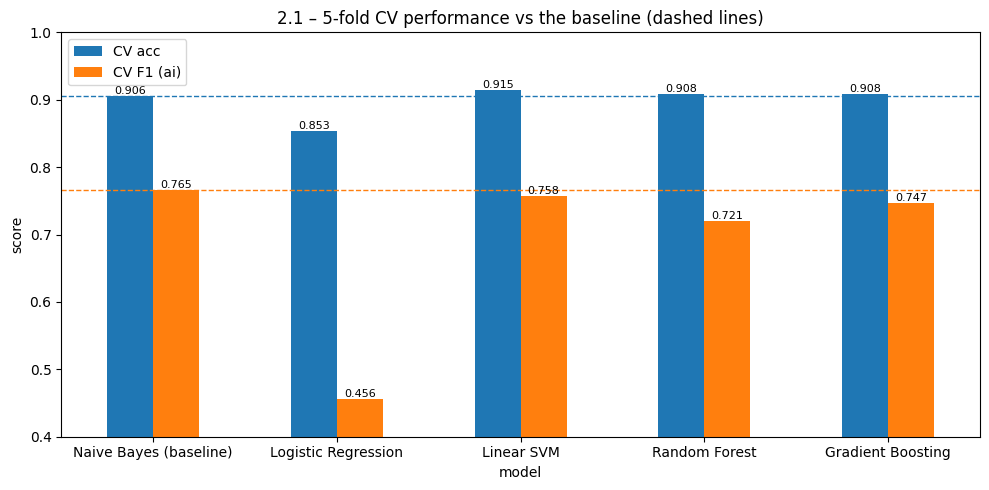

In [23]:
plot_df = results_df[results_df['group'].isin(['baseline', '2.1 models'])][['CV acc', 'CV F1 (ai)']]
ax = plot_df.plot(kind='bar', figsize=(10, 5), rot=0, color=['tab:blue', 'tab:orange'])
ax.axhline(baseline_row['CV acc'], color='tab:blue', linestyle='--', linewidth=1)
ax.axhline(baseline_row['CV F1 (ai)'], color='tab:orange', linestyle='--', linewidth=1)
ax.set_ylim(0.4, 1.0)
ax.set_title("2.1 – 5-fold CV performance vs the baseline (dashed lines)")
ax.set_ylabel("score")
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

Linear SVM leads the four models with 91.5% cross-validated accuracy against 90.6% for the baseline, and with 0.91 precision on the AI class. Random Forest and Gradient Boosting also beat the baseline on accuracy. None of the four catches more AI papers than the baseline, though. Their cross-validated F1 for the AI class sits between 0.72 and 0.76 against 0.765, and Logistic Regression finds only 23% of the AI papers. All four lean towards the majority class, so a change of algorithm alone does not fix the problem.



## 2.2 Performance enhancement: balancing the classes with SMOTE

The results in 2.1 point to class imbalance, with only 21% of the abstracts in the AI class. SMOTE creates synthetic AI examples between real AI abstracts and their nearest neighbours, which balances the training data at 50/50 (Chawla et al., 2002). The textbook applies the same method to imbalanced text data (Cuantum Technologies, 2024, section 13.2.3).

To stop data leakage, SMOTE sits inside an imblearn pipeline of TF-IDF, then SMOTE, then the classifier. The pipeline runs SMOTE on the training folds only and skips SMOTE during prediction.

In [24]:
# What SMOTE does to the training set
tfidf_demo = TfidfVectorizer(min_df=2, ngram_range=(1, 2))
X_train_vec = tfidf_demo.fit_transform(X_train_text)
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_vec, y_train)

print("Before SMOTE:", dict(pd.Series(y_train).value_counts().rename({0: 'classical', 1: 'ai'})))
print("After SMOTE: ", dict(pd.Series(y_train_balanced).value_counts().rename({0: 'classical', 1: 'ai'})))

Before SMOTE: {'classical': np.int64(712), 'ai': np.int64(188)}
After SMOTE:  {'classical': np.int64(712), 'ai': np.int64(712)}


In [25]:
smote_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVM': LinearSVC(max_iter=5000),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}
fitted_smote = {}

for name, clf in smote_models.items():
    pipeline = ImbPipeline([
        ('vectorizer', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
        ('smote', SMOTE(random_state=42)),
        ('classifier', clf)
    ])
    fitted_smote[name], _ = evaluate_model(name + ' + SMOTE', pipeline, '2.2 SMOTE')
    print("done:", name)

results_df = pd.DataFrame(results).set_index('model')
results_df.drop(columns='group').round(3)

done: Logistic Regression
done: Linear SVM
done: Random Forest
done: Gradient Boosting


,train acc,test acc,precision (ai),recall (ai),F1 (ai),CV acc,CV F1 (ai)
model,,,,,,,
Naive Bayes (baseline),0.978,0.889,0.739,0.723,0.731,0.906,0.765
Logistic Regression,0.884,0.836,0.917,0.234,0.373,0.853,0.456
Linear SVM,1.000,0.907,0.906,0.617,0.734,0.915,0.758
Random Forest,1.000,0.893,1.000,0.489,0.657,0.908,0.721
Gradient Boosting,0.988,0.893,0.829,0.617,0.707,0.908,0.747
Logistic Regression + SMOTE,0.990,0.884,0.744,0.681,0.711,0.908,0.766
Linear SVM + SMOTE,0.999,0.893,0.795,0.660,0.721,0.919,0.782
Random Forest + SMOTE,1.000,0.898,0.962,0.532,0.685,0.916,0.751
Gradient Boosting + SMOTE,0.978,0.893,0.795,0.660,0.721,0.908,0.749


### Before vs after SMOTE

In [26]:
compare = pd.DataFrame({
    'CV F1 before': results_df.loc[list(models), 'CV F1 (ai)'].values,
    'CV F1 after SMOTE': results_df.loc[[m + ' + SMOTE' for m in models], 'CV F1 (ai)'].values,
    'recall before': results_df.loc[list(models), 'recall (ai)'].values,
    'recall after SMOTE': results_df.loc[[m + ' + SMOTE' for m in models], 'recall (ai)'].values,
    'CV acc before': results_df.loc[list(models), 'CV acc'].values,
    'CV acc after SMOTE': results_df.loc[[m + ' + SMOTE' for m in models], 'CV acc'].values,
}, index=list(models))
compare['F1 gain'] = compare['CV F1 after SMOTE'] - compare['CV F1 before']
compare.round(3)

,CV F1 before,CV F1 after SMOTE,recall before,recall after SMOTE,CV acc before,CV acc after SMOTE,F1 gain
Logistic Regression,0.456,0.766,0.234,0.681,0.853,0.908,0.309
Linear SVM,0.758,0.782,0.617,0.660,0.915,0.919,0.024
Random Forest,0.721,0.751,0.489,0.532,0.908,0.916,0.031
Gradient Boosting,0.747,0.749,0.617,0.660,0.908,0.908,0.001


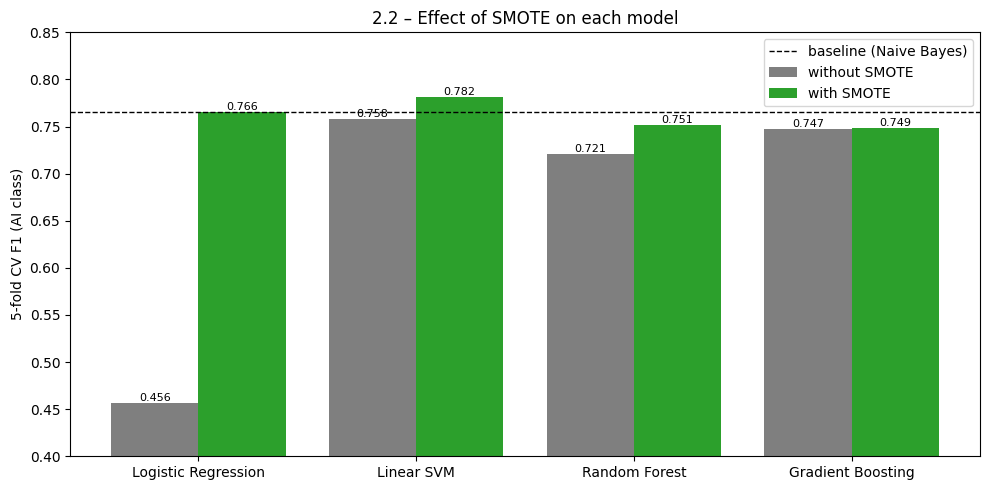

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(models))
ax.bar(x - 0.2, compare['CV F1 before'], 0.4, label='without SMOTE', color='tab:gray')
ax.bar(x + 0.2, compare['CV F1 after SMOTE'], 0.4, label='with SMOTE', color='tab:green')
ax.axhline(baseline_row['CV F1 (ai)'], color='black', linestyle='--', linewidth=1, label='baseline (Naive Bayes)')
ax.set_xticks(x)
ax.set_xticklabels(models.keys())
ax.set_ylim(0.4, 0.85)
ax.set_ylabel("5-fold CV F1 (AI class)")
ax.set_title("2.2 – Effect of SMOTE on each model")
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
ax.legend()
plt.tight_layout()
plt.show()

### Choosing the best configuration
I rank on **cross-validated F1 for the AI class**, because it balances catching AI papers (recall) against false alarms (precision), and because CV is more reliable than one 225-abstract test set.

In [28]:
ranking = results_df.sort_values('CV F1 (ai)', ascending=False)[['test acc', 'F1 (ai)', 'CV acc', 'CV F1 (ai)']]
display(ranking.round(3))
best_name = ranking.index[0]
print("Best configuration:", best_name)

,test acc,F1 (ai),CV acc,CV F1 (ai)
model,,,,
Linear SVM + SMOTE,0.893,0.721,0.919,0.782
Logistic Regression + SMOTE,0.884,0.711,0.908,0.766
Naive Bayes (baseline),0.889,0.731,0.906,0.765
Linear SVM,0.907,0.734,0.915,0.758
Random Forest + SMOTE,0.898,0.685,0.916,0.751
Gradient Boosting + SMOTE,0.893,0.721,0.908,0.749
Gradient Boosting,0.893,0.707,0.908,0.747
Random Forest,0.893,0.657,0.908,0.721
Logistic Regression,0.836,0.373,0.853,0.456


Best configuration: Linear SVM + SMOTE


BASELINE – Naive Bayes
              precision    recall  f1-score   support

   classical      0.927     0.933     0.930       178
          ai      0.739     0.723     0.731        47

    accuracy                          0.889       225
   macro avg      0.833     0.828     0.831       225
weighted avg      0.888     0.889     0.888       225

BEST – Linear SVM + SMOTE
              precision    recall  f1-score   support

   classical      0.914     0.955     0.934       178
          ai      0.795     0.660     0.721        47

    accuracy                          0.893       225
   macro avg      0.854     0.807     0.827       225
weighted avg      0.889     0.893     0.890       225



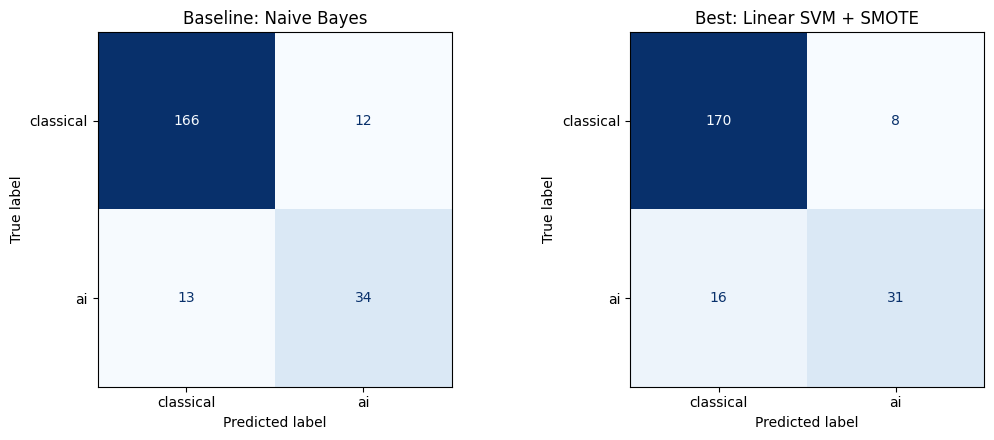

In [29]:
best_pipeline = fitted_smote['Linear SVM']
y_pred_best = best_pipeline.predict(X_test_text)
y_pred_base = baseline.predict(X_test_text)

print("BASELINE – Naive Bayes")
print(classification_report(y_test, y_pred_base, target_names=['classical', 'ai'], digits=3))
print("BEST – Linear SVM + SMOTE")
print(classification_report(y_test, y_pred_best, target_names=['classical', 'ai'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, preds, title in [(axes[0], y_pred_base, 'Baseline: Naive Bayes'),
                         (axes[1], y_pred_best, 'Best: Linear SVM + SMOTE')]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds, labels=[0, 1]),
                           display_labels=['classical', 'ai']).plot(ax=ax, cmap=plt.cm.Blues, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

### How SMOTE improves the design

SMOTE raises the cross-validated AI F1 for three of the four models. Logistic Regression gains 0.31, with AI recall rising from 0.23 to 0.68. Random Forest gains 0.03 and Linear SVM gains 0.02. Gradient Boosting stays level, because boosting already corrects part of the imbalance.

The best configuration is TF-IDF, then SMOTE, then Linear SVM. The model reaches 91.9% cross-validated accuracy and an AI F1 of 0.782, against 90.6% and 0.765 for the baseline, and cuts false alarms from 12 to 8. On the single test set of 225 abstracts, the model misses 3 more AI papers than the baseline. With 47 AI papers in the test set, two or three abstracts swing the score, so the choice rests on the 5-fold results.

## 2.3 Deploying the best model in a web interface

I use **Flask**, the textbook's deployment framework (Ch. 12.4 / 13.4), with an `app.py`, an HTML template and the model loaded with `pickle`. The best configuration is retrained on all 1,125 abstracts first.


In [30]:
os.makedirs('models', exist_ok=True)

final_model = ImbPipeline([
    ('vectorizer', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
    ('smote', SMOTE(random_state=42)),
    ('classifier', LinearSVC(max_iter=5000))
])
final_model.fit(X, y)

with open('models/best_model.pickle', 'wb') as file:
    pickle.dump(final_model, file)
print("Saved models/best_model.pickle")

Saved models/best_model.pickle



The app has to clean incoming text in **exactly** the same way as the training data. Otherwise the model would see words in a different form from what it learned. So `denoise_text` and `preprocess_text` are copied in unchanged.

In [31]:
%%writefile app.py
from flask import Flask, request, render_template
import pickle
import re
import string
import unicodedata

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

app = Flask(__name__)

# Load the best model (TF-IDF -> SMOTE -> Linear SVM pipeline)
with open('models/best_model.pickle', 'rb') as file:
    model = pickle.load(file)

# The text must be cleaned exactly like the training data
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english')).union({
    'paper', 'study', 'article', 'research', 'result', 'results', 'method', 'methods',
    'conclusion', 'conclusions', 'objective', 'background', 'finding', 'findings',
    'propose', 'proposed', 'show', 'shows', 'also', 'however', 'using', 'use', 'used',
    'based', 'approach', 'author', 'authors', 'within', 'among', 'may', 'well', 'one', 'two'
})


def denoise_text(text):
    text = re.sub(r'(copyright\s*)?©.*$', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'\[[^\]]*\]', ' ', text)
    text = re.sub(r'^\s*(abstract|background)\s*[.:]?', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'[‐-―−]', ' ', text)
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('ascii')
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def preprocess_text(text):
    text = text.lower()
    tokens = nltk.word_tokenize(text)
    tokens = [word for word in tokens
              if word not in string.punctuation and word not in stop_words and len(word) > 2]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    tokens = [word for word in tokens if word not in stop_words]
    return ' '.join(tokens)


@app.route('/')
def home():
    return render_template('index.html')


@app.route('/classify', methods=['POST'])
def classify():
    abstract = request.form.get('abstract', '').strip()
    if not abstract:
        return render_template('index.html', error="Please enter a research abstract first.")

    clean_text = preprocess_text(denoise_text(abstract))
    prediction = model.predict([clean_text])[0]
    label = 'artificial intelligence' if prediction == 1 else 'classical research'

    return render_template('index.html', abstract=abstract, prediction=label)


if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5000, debug=False)

Writing app.py


HTML template (`templates/index.html`)


In [32]:
os.makedirs('templates', exist_ok=True)

In [33]:
%%writefile templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Researchly Research Abstract Classifier</title>
    <link href="https://fonts.googleapis.com/css2?family=Source+Sans+3:wght@400;600;700&display=swap" rel="stylesheet">
    <style>
        body {
            margin: 0;
            background: #ffffff;
            color: #31333f;
            font-family: "Source Sans 3", "Source Sans Pro", sans-serif;
        }
        .container {
            max-width: 704px;
            margin: 0 auto;
            padding: 60px 16px 40px;
        }
        h1 {
            font-size: 44px;
            font-weight: 700;
            line-height: 1.2;
            margin: 0 0 24px;
        }
        p.description {
            font-size: 16px;
            margin: 0 0 24px;
        }
        label {
            display: block;
            font-size: 14px;
            margin-bottom: 8px;
        }
        textarea {
            width: 100%;
            box-sizing: border-box;
            min-height: 170px;
            padding: 12px 16px;
            border: 1px solid transparent;
            border-radius: 8px;
            background: #f0f2f6;
            color: #31333f;
            font-family: inherit;
            font-size: 14px;
            line-height: 1.6;
            resize: vertical;
        }
        textarea:focus {
            outline: none;
            border-color: #ff4b4b;
        }
        button {
            margin-top: 16px;
            padding: 8px 12px;
            background: #ffffff;
            color: #31333f;
            border: 1px solid rgba(49, 51, 63, 0.2);
            border-radius: 8px;
            font-family: inherit;
            font-size: 14px;
            cursor: pointer;
        }
        button:hover {
            border-color: #ff4b4b;
            color: #ff4b4b;
        }
        h2 {
            font-size: 28px;
            font-weight: 600;
            margin: 40px 0 16px;
        }
        .success, .error {
            padding: 16px;
            border-radius: 8px;
            font-size: 16px;
        }
        .success {
            background: rgba(33, 195, 84, 0.1);
            color: #177233;
        }
        .error {
            background: rgba(255, 43, 43, 0.09);
            color: #7d353b;
            margin-top: 16px;
        }
    </style>
</head>
<body>
    <div class="container">
        <h1>Researchly Research Abstract Classifier</h1>
        <p class="description">This app classifies research abstracts as either AI-related or classical research.</p>

        <form method="POST" action="{{ url_for('classify') }}">
            <label for="abstract">Enter research abstract:</label>
            <textarea id="abstract" name="abstract" required>{{ abstract or '' }}</textarea>
            <button type="submit">Classify Abstract</button>
        </form>

        {% if error %}
            <div class="error">{{ error }}</div>
        {% endif %}

        {% if prediction %}
            <h2>Prediction</h2>
            <div class="success">The abstract is classified as: {{ prediction }}</div>
        {% endif %}
    </div>
</body>
</html>

Writing templates/index.html


Testing the app with Flask's test client, then launching it. In Colab the link opens the app in a new tab.

In [34]:
if 'app' in sys.modules:
    del sys.modules['app']
from app import app as flask_app

client = flask_app.test_client()
tests = {
    'AI healthcare abstract': ("Artificial intelligence (AI) has become a transformative technology in healthcare by enabling "
                               "more accurate diagnosis, predictive analytics, and personalised treatment planning. Machine "
                               "learning algorithms can analyse large volumes of medical data to identify patterns that assist "
                               "clinicians in detecting diseases at earlier stages."),
    'Classical economics abstract': ("This paper examines how monetary policy shocks affect inflation expectations and interest "
                                     "rates in emerging economies using a structural vector autoregression and quarterly data."),
}
for name, text in tests.items():
    response = client.post('/classify', data={'abstract': text})
    page = response.data.decode()
    result = re.search(r'classified as: ([a-z ]+)', page).group(1)
    print(f"{name:30s} -> status {response.status_code}, classified as: {result}")

AI healthcare abstract         -> status 200, classified as: artificial intelligence
Classical economics abstract   -> status 200, classified as: classical research


In [35]:
server = subprocess.Popen([sys.executable, 'app.py'])
time.sleep(5)

try:
    from google.colab.output import eval_js
    print("Open the Researchly app here:", eval_js("google.colab.kernel.proxyPort(5000)"))
except ImportError:
    print("Running locally: open http://127.0.0.1:5000")

Open the Researchly app here: https://5000-m-s-usc1c7-9dt87iwjuibw-c.us-central1.prod.r.colab.dev


The app keeps running in the background while you test it. When you're finished, remove the `#` in the next cell and run it to stop the server.

In [36]:
# server.terminate()     # remove the # and run this cell to stop the web app


### Question 3

## 3.1

In [37]:
article_rows = []
with zipfile.ZipFile(corpus_zip_path) as z:
    for name in sorted(z.namelist()):
        if name.endswith('.txt'):
            content = z.read(name).decode('utf-8')
            article_rows.append({'file_name': name.split('/')[-1], 'content': content})

articles = pd.DataFrame(article_rows)
articles.insert(0, 'article_id', range(1, len(articles) + 1))
articles['n_characters'] = articles['content'].str.len()
articles['n_words'] = articles['content'].str.split().str.len()
articles['n_lines'] = articles['content'].str.count('\n') + 1

print(f"{len(articles)} articles loaded")
articles

5 articles loaded


,article_id,file_name,content,n_characters,n_words,n_lines
0,1,research_1.txt,The purposes of this article are to position mixed methods research\r\n(mixed research is a synonym) as the natural ...,38598,5602,439
1,2,research_2.txt,"Now I see it, now I don’t:\r\nresearcher’s position and\r\nreflexivity in qualitative\r\nresearch\r\nRoni Berger\r\n...",16279,2416,176
2,3,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\r\nINSTRUCTIONAL DESIGN AND DEVELOPMENT\r\nRita C. Richey\r\nWayne State Universi...,26521,3828,368
3,4,research_4.txt,Abstract\r\nCronbach’s alpha is a statistic commonly quoted by authors to demonstrate that tests and scales that hav...,39072,5922,123
4,5,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulation in Qualitative\r\nResearch\r\nPatricia Fusch\r\nWalden University\...,27142,4027,312



The five articles cover mixed methods research (article 1), researcher position and reflexivity (article 2), developmental research in instructional design (article 3), Cronbach's alpha in science education (article 4) and Denzin's triangulation (article 5). The brief describes the corpus as AI research, but all five articles deal with research methodology. The analysis below reports the themes in the text.

## 3.2 Denoising the article content


The articles come from PDF files, so most of the noise sits in the layout. Article 1 contains two copies of the full text. Running page headers such as Journal of Social Change 20 repeat on every page, and one header sits inside a sentence. Title, author and affiliation blocks, email addresses, publisher web text, in-text citations such as (Author, 1998) and hidden control characters complete the list.

A five-stage pipeline handles the noise in order: characters, lines, inline text, sentences and words. The regular expressions follow the textbook approach (Cuantum Technologies, 2024, section 2.3). The first four stages keep readable sentences for the summaries. The fifth stage produces lemmatised word tokens, with part-of-speech tags from nltk.pos_tag guiding the WordNet lemmatizer (Cuantum Technologies, 2024, section 2.2).

Character normalisation and layout (line-level) cleaning


In [38]:
JUNK_LINE = re.compile(r'^(full size image|similar content being viewed by others|article open access|article|'
                       r'keywords|corresponding author:?|abstract|introduction)$', re.I)
PAGE_LINE = re.compile(r'''^(
      \d+(\.\d+)*\s*[•·]?.*[•·].*                                   # 1100 • RICHEY, KLEIN, NELSON
    | .*\b(journal\ of|qualitative\ research|educational\ researcher)\b.*\d+.*   # Journal of Social Change 20
    | \d+\s+[A-Z][A-Z\ ]+ | [A-Z][A-Z\ ]+\s+\d+(\s+\d+)?             # 16 EDUCATIONAL RESEARCHER / OCTOBER 2004 15
    | [A-Z][a-z]+\s+\d{3,4}                                           # Berger 221
    | \d+ | \d{1,2}\s+[A-Z][a-z]+\s+\d{4}                              # page numbers, dates
    | chapter\s*©\s*\d{4}
)$''', re.X | re.I)

def normalise_characters(text):
    # Stage 1: one consistent set of characters
    text = unicodedata.normalize('NFKC', text)                    # unify unicode forms
    text = text.replace('﻿', '').replace('\r', '')           # byte-order marks, Windows line endings
    text = re.sub(r'[\x00-\x08\x0b-\x1f\x7f]', ' ', text)         # control characters (e.g. \x01 bullets)
    return text

def remove_layout_noise(text):
    # Stage 2: drop header/footer, title, author and publisher lines
    # a running header glued into the middle of a sentence
    text = re.sub(r'[A-Z][A-Za-z ]+,\s*Vol\.\s*\d+,\s*No\.\s*\d+,\s*pp\.\s*[\d–-]+', ' ', text)
    lines = [line.strip() for line in text.split('\n')]

    # if "Abstract" appears near the top, everything before it is the title/author block
    for i, line in enumerate(lines[:15]):
        if line.lower() == 'abstract':
            lines = lines[i + 1:]
            break

    counts = collections.Counter(line for line in lines if line)
    kept, removed = [], []
    after_sentence_end, skip_next, skip_until_intro = True, False, False

    for line in lines:
        if not line:
            after_sentence_end = True
            continue
        low = line.lower()
        drop = False
        if re.match(r'^(fig\.?|figure)\s*\d+$', low):              # figure label -> caption follows
            drop, skip_next = True, True
        elif skip_next:                                            # keyword list / address / caption
            drop, skip_next = True, False
        elif low.startswith('similar content being viewed'):      # publisher website block
            drop, skip_until_intro = True, True
        elif skip_until_intro:
            drop = True
            skip_until_intro = (low != 'introduction')
        elif low in ('keywords', 'corresponding author:'):
            drop, skip_next = True, True
        elif low.startswith('keywords:') or re.match(r'^by [A-Z]', line):
            drop = True
        elif counts[line] >= 3 and len(line.split()) <= 8:          # repeated running header/footer
            drop = True
        elif (JUNK_LINE.match(line) or (PAGE_LINE.match(line) and len(line.split()) <= 8)
              or '@' in line or re.search(r'\d{6,}', line)):
            drop = True
        else:
            long_words = [w for w in line.split() if len(w) > 3]
            title_case = bool(long_words) and sum(w[0].isupper() for w in long_words) / len(long_words) >= 0.7
            if title_case and len(line.split()) >= 2 and not re.search(r'[.?!,;]$', line):
                drop = True                                          # titles / headings / names
            elif (after_sentence_end and len(line.split()) <= 7 and (line[0].isupper() or line[0].isdigit())
                  and not re.search(r'[.?!,;:)"”]$', line)):
                drop = True                                          # short headings
        if drop:
            removed.append(line)
            continue
        kept.append(line)
        after_sentence_end = bool(re.search(r'[.?!:]["”’)]?$', line))

    return ' '.join(kept), removed

Inline noise


In [39]:
CITATION = re.compile(r'\((?:[^()]*?\b(?:19|20)\d{2}[a-z]?\b[^()]*?|\s*pp?\.\s*[\d–\-]+\s*)\)')

def remove_inline_noise(text):
    text = re.sub(r'http\S+|www\.\S+|\b10\.\d{4,}/\S+', ' ', text)                # URLs and DOIs
    text = re.sub(r'\S+@\S+', ' ', text)                                          # emails
    text = CITATION.sub(' ', text)                                                # (Author, 1998), (p. 237)
    text = re.sub(r'\b(?:TABLE|Table|FIGURE|Figure|Fig\.)\s+\d+(\.\d+)*\.?', ' ', text)  # table / figure labels
    text = re.sub(r'\be\.g\.', 'eg', text)                                        # abbreviations that would
    text = re.sub(r'\bi\.e\.', 'ie', text)                                        # break sentence splitting
    text = re.sub(r'\bet al\.', 'et al', text)
    text = re.sub(r'\bcf\.', 'cf', text)
    text = re.sub(r'[“”]', '"', text)                                             # straight quotes
    text = re.sub(r"[‘’]", "'", text)
    text = re.sub(r'[‐‑–—]', '-', text)                                           # one kind of dash
    text = re.sub(r'(?<=[a-z][.,;])\d{1,2}\b', '', text)                          # footnote markers: research.5
    text = re.sub(r'\s+([.,;:])', r'\1', text)                                    # space left before punctuation
    text = re.sub(r'\s+', ' ', text).strip()
    return text

Sentence segmentation and de-duplication


In [40]:
def split_and_deduplicate(text):
    seen, sentences = set(), []
    for sentence in sent_tokenize(text):
        if re.match(r'^\d+(\.\d+)+\s', sentence) or len(sentence.split()) < 4:
            continue
        key = re.sub(r'\W+', '', sentence.lower())
        if key not in seen:
            seen.add(key)
            sentences.append(sentence)
    return sentences

Linguistic normalisation for word-level analysis


In [41]:
english_stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def to_wordnet_pos(tag):
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

def normalise_words(text):
    tokens = word_tokenize(text.lower())
    words = []
    for word, tag in nltk.pos_tag(tokens):
        if not word.isalpha() or word in english_stop_words or len(word) <= 2:
            continue
        lemma = lemmatizer.lemmatize(word, to_wordnet_pos(tag))
        if lemma not in english_stop_words and len(lemma) > 2:
            words.append(lemma)
    return words

### Running the full pipeline

In [42]:
def denoise_article(raw_text):
    text = normalise_characters(raw_text)
    text, removed_lines = remove_layout_noise(text)
    n_citations = len(CITATION.findall(text))
    text = remove_inline_noise(text)
    n_raw_sentences = len(sent_tokenize(text))
    sentences = split_and_deduplicate(text)
    return pd.Series({
        'sentences': sentences,
        'clean_content': ' '.join(sentences),
        'lines_removed': len(removed_lines),
        'citations_removed': n_citations,
        'sentences_dropped': n_raw_sentences - len(sentences),
        'removed_examples': removed_lines[:8],
    })

articles = articles.join(articles['content'].apply(denoise_article))
articles['sentence_tokens'] = articles['sentences'].apply(lambda ss: [normalise_words(s) for s in ss])
articles['tokens'] = articles['sentence_tokens'].apply(lambda st: [w for s in st for w in s])

articles['clean_words'] = articles['clean_content'].str.split().str.len()
articles['n_sentences'] = articles['sentences'].str.len()
articles['n_tokens'] = articles['tokens'].str.len()

noise_report = articles[['article_id', 'n_words', 'lines_removed', 'citations_removed',
                         'sentences_dropped', 'clean_words', 'n_sentences', 'n_tokens']].copy()
noise_report['% words removed'] = ((1 - noise_report['clean_words'] / noise_report['n_words']) * 100).round(1)
noise_report

,article_id,n_words,lines_removed,citations_removed,sentences_dropped,clean_words,n_sentences,n_tokens,% words removed
0,1,5602,24,58,79,2564,79,1431,54.2
1,2,2416,14,31,0,2165,57,1103,10.4
2,3,3828,34,55,4,3483,155,1956,9.0
3,4,5922,19,67,0,5604,179,3008,5.4
4,5,4027,36,100,1,3559,157,1989,11.6


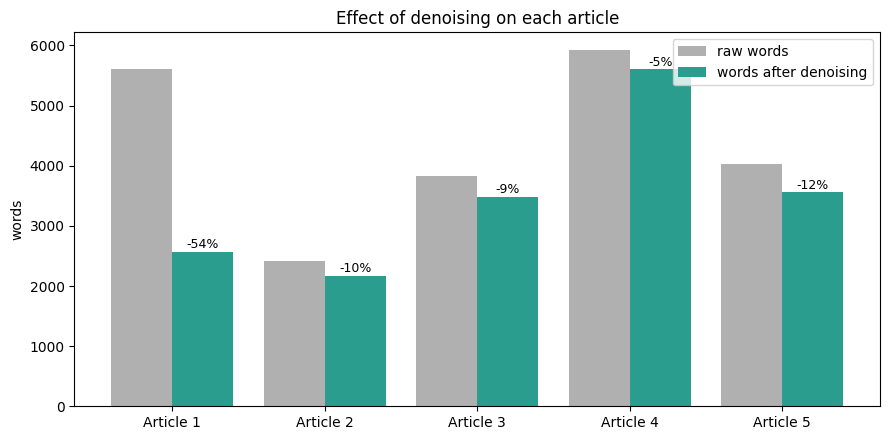

In [43]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(articles))
ax.bar(x - 0.2, articles['n_words'], 0.4, label='raw words', color='#b0b0b0')
ax.bar(x + 0.2, articles['clean_words'], 0.4, label='words after denoising', color='#2a9d8f')
ax.set_xticks(x)
ax.set_xticklabels([f"Article {i}" for i in articles['article_id']])
ax.set_ylabel("words")
ax.set_title("Effect of denoising on each article")
for i, (raw, clean) in enumerate(zip(articles['n_words'], articles['clean_words'])):
    ax.text(i + 0.2, clean + 60, f"-{(1 - clean / raw) * 100:.0f}%", ha='center', fontsize=9)
ax.legend()
plt.tight_layout()
plt.show()

The pipeline removes 127 layout lines, 311 citations and 79 duplicate sentences. Article 1 shrinks by 54% because the pipeline drops the second copy. The other articles shrink by 5% to 12%. The output keeps clean sentences with no author names or citations to distort the summaries and topics.

## 3.3

TextRank links sentences by similarity and ranks them with PageRank, so the most central sentences form the summary (Mihalcea and Tarau, 2004). The textbook covers TextRank as an extractive technique (Cuantum Technologies, 2024, section 8.1.3). The textbook function build_similarity_matrix passes word lists to cosine_distance, and the call raises a ValueError. This version converts each pair of sentences into word-count vectors first.


In [44]:
article1 = articles.loc[0]
sentences = article1['sentences']
sentence_words = article1['sentence_tokens']

def sentence_similarity(words1, words2):
    if not words1 or not words2:
        return 0.0
    vocabulary = list(set(words1 + words2))
    vector1 = [words1.count(w) for w in vocabulary]
    vector2 = [words2.count(w) for w in vocabulary]
    return 1 - cosine_distance(vector1, vector2)

def build_similarity_matrix(sentence_words):
    n = len(sentence_words)
    similarity_matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i != j:
                similarity_matrix[i][j] = sentence_similarity(sentence_words[i], sentence_words[j])
    return similarity_matrix

def textrank(sentences, sentence_words, num_sentences=6):
    similarity_matrix = build_similarity_matrix(sentence_words)
    similarity_graph = nx.from_numpy_array(similarity_matrix)
    scores = nx.pagerank(similarity_graph)
    top_ids = sorted(scores, key=scores.get, reverse=True)[:num_sentences]

    summary_ids = sorted(top_ids)
    return summary_ids, scores, similarity_matrix

summary_ids, scores, similarity_matrix = textrank(sentences, sentence_words, num_sentences=6)
summary_article1 = ' '.join(sentences[i] for i in summary_ids)

words_before = len(article1['clean_content'].split())
words_after = len(summary_article1.split())
print(f"Article 1: {len(sentences)} sentences, {words_before} words  ->  summary: {len(summary_ids)} sentences, "
      f"{words_after} words ({words_after / words_before:.0%} of the article)\n")
for rank, i in enumerate(summary_ids, 1):
    print(f"[{rank}] (sentence {i}, score {scores[i]:.4f}) {sentences[i]}\n")

Article 1: 79 sentences, 2564 words  ->  summary: 6 sentences, 182 words (7% of the article)

[1] (sentence 0, score 0.0248) The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.

[2] (sentence 20, score 0.0235) Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.

[3] (sentence 21, score 0.0241) We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful.

[4] (sentence 23, score 0.0219) If you visualize a continuum with qualitative research anchored at one pole and quanti

### Visualisation 1 – What the article talks about most

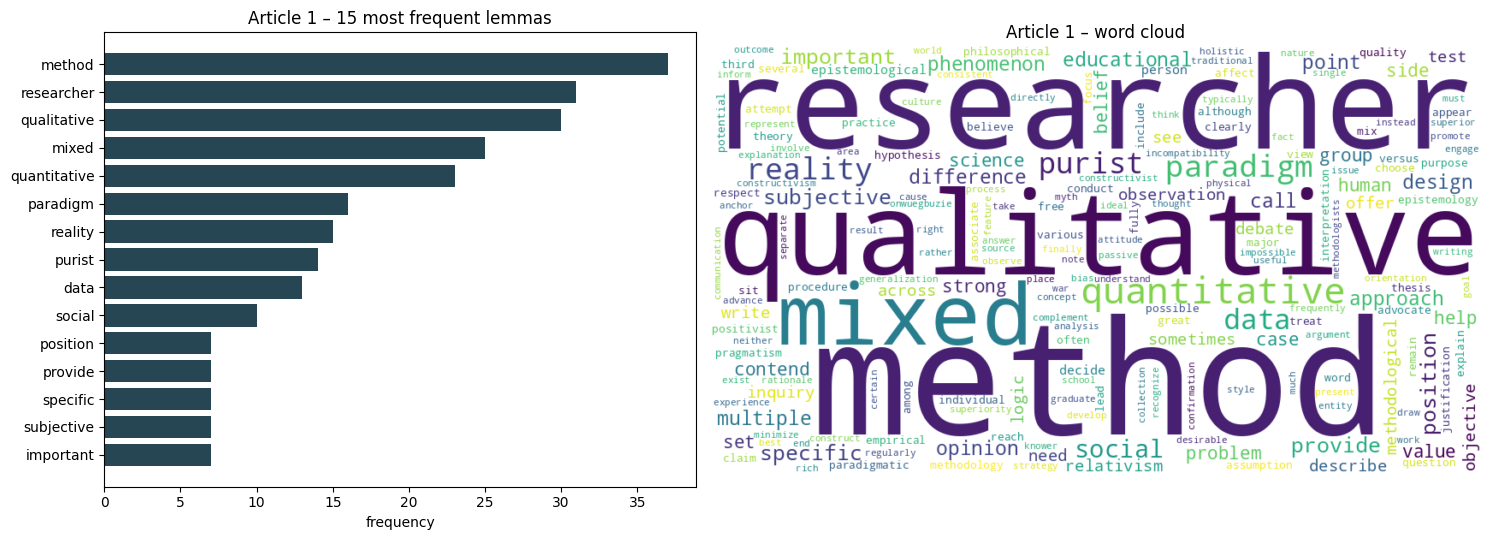

In [45]:
# generic academic words appear in every article and say nothing about the topic, so I leave them out of the charts
academic_words = {'research', 'study', 'use', 'one', 'may', 'also', 'would', 'could', 'however', 'article',
                  'paper', 'two', 'many', 'well', 'make', 'way', 'different', 'example', 'first', 'within'}

freq = FreqDist(w for w in article1['tokens'] if w not in academic_words)
top_words = freq.most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.3]})
words, counts = zip(*top_words)
axes[0].barh(words[::-1], counts[::-1], color='#264653')
axes[0].set_title("Article 1 – 15 most frequent lemmas")
axes[0].set_xlabel("frequency")

cloud = WordCloud(width=900, height=500, background_color='white', colormap='viridis',
                  random_state=42).generate_from_frequencies(freq)
axes[1].imshow(cloud, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title("Article 1 – word cloud")
plt.tight_layout()
plt.show()

### Visualisation 2 – TextRank score of every sentence
The red bars are the sentences chosen for the summary. This shows **where** in the article the key ideas sit.

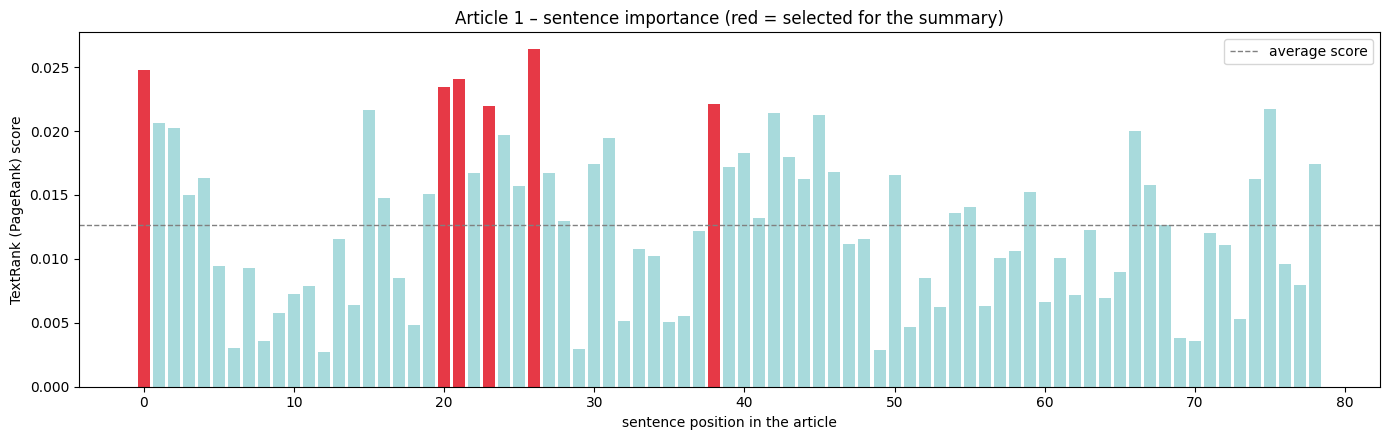

In [46]:
score_values = [scores[i] for i in range(len(sentences))]
colours = ['#e63946' if i in summary_ids else '#a8dadc' for i in range(len(sentences))]

plt.figure(figsize=(14, 4.5))
plt.bar(range(len(sentences)), score_values, color=colours)
plt.axhline(np.mean(score_values), color='grey', linestyle='--', linewidth=1, label='average score')
plt.xlabel("sentence position in the article")
plt.ylabel("TextRank (PageRank) score")
plt.title("Article 1 – sentence importance (red = selected for the summary)")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

TextRank cuts article 1 from 79 sentences to 6, about 7% of the text. The summary presents mixed methods research as the third research paradigm, next to qualitative and quantitative research, with pragmatism as the philosophy behind the approach. The word cloud agrees, with researcher, method, qualitative, mixed, quantitative and paradigm in the lead. All six summary sentences come from the first half of the article, the part with the main argument.


3.4

For a group of articles you want the main themes and the sentences expressing each theme. Latent Semantic Analysis delivers both (Cuantum Technologies, 2024, section 7.1). The method builds a TF-IDF matrix of every sentence, then Truncated SVD reduces the matrix to a few concepts. The top terms of each concept name the theme, and the three sentences with the highest loading on a concept summarise the theme (Cuantum Technologies, 2024, section 8.1.3). The matrix leaves out generic academic words so they do not blur the themes.

In [47]:
remaining = articles[articles['article_id'] != 1]

agg_sentences, agg_article, agg_docs = [], [], []
for _, row in remaining.iterrows():
    for sentence, words in zip(row['sentences'], row['sentence_tokens']):
        agg_sentences.append(sentence)
        agg_article.append(row['article_id'])
        agg_docs.append(' '.join(w for w in words if w not in academic_words))

lsa_vectorizer = TfidfVectorizer(min_df=2, ngram_range=(1, 2))
X_lsa = lsa_vectorizer.fit_transform(agg_docs)
lsa_terms = lsa_vectorizer.get_feature_names_out()
print(f"Sentences from Articles 2–5: {X_lsa.shape[0]},  vocabulary (uni + bigrams): {X_lsa.shape[1]}")

Sentences from Articles 2–5: 548,  vocabulary (uni + bigrams): 1377


In [48]:
for k in [4, 5, 6]:
    test = TruncatedSVD(n_components=k, random_state=42).fit(X_lsa)
    print(f"k = {k}")
    for c, comp in enumerate(test.components_):
        comp = comp if comp.max() >= -comp.min() else -comp
        print(f"   concept {c + 1}: {', '.join(lsa_terms[comp.argsort()[::-1][:6]])}")

k = 4
   concept 1: alpha, cronbach, cronbach alpha, data, development, value
   concept 2: data, triangulation, design, method, multiple, researcher
   concept 3: development, process, design, instructional, developmental, design development
   concept 4: researcher, reflexivity, experience, qualitative, participant, personal
k = 5
   concept 1: alpha, cronbach, cronbach alpha, data, development, value
   concept 2: data, triangulation, design, method, multiple, researcher
   concept 3: development, process, design, instructional, developmental, design development
   concept 4: researcher, reflexivity, experience, qualitative, knowledge, personal
   concept 5: science education, education, science, field, journal, publish
k = 6
   concept 1: alpha, cronbach, cronbach alpha, data, development, value
   concept 2: data, triangulation, design, method, multiple, researcher
   concept 3: development, process, design, instructional, developmental, design development
   concept 4: researcher

In [49]:
n_themes = 4
lsa = TruncatedSVD(n_components=n_themes, random_state=42)
sentence_topic = lsa.fit_transform(X_lsa)

# SVD signs are arbitrary – flip each concept so its strongest terms are positive
components = lsa.components_.copy()
for c in range(n_themes):
    if components[c].max() < -components[c].min():
        components[c] *= -1
        sentence_topic[:, c] *= -1

theme_terms = {}
for c in range(n_themes):
    top = components[c].argsort()[::-1][:10]
    theme_terms[c] = [(lsa_terms[i], components[c][i]) for i in top]

pd.DataFrame({f"Concept {c + 1}": [t for t, _ in theme_terms[c]] for c in range(n_themes)})

,Concept 1,Concept 2,Concept 3,Concept 4
0,alpha,data,development,researcher
1,cronbach,triangulation,process,reflexivity
2,cronbach alpha,design,design,experience
3,data,method,instructional,qualitative
4,development,multiple,developmental,participant
5,value,researcher,design development,personal
6,instrument,process,evaluation,knowledge
7,design,denzin,product,share
8,science,data triangulation,development evaluation,part
9,triangulation,methodological triangulation,model,bias


In [50]:
theme_names = {}
for c in range(n_themes):
    words = [t for t, _ in theme_terms[c][:12]]
    if 'alpha' in words or 'cronbach' in words:
        theme_names[c] = 'Reliability & Cronbach\'s alpha'
    elif 'triangulation' in words:
        theme_names[c] = 'Triangulation & data sources'
    elif 'developmental' in words or 'instructional' in words:
        theme_names[c] = 'Developmental research in instructional design'
    elif 'reflexivity' in words:
        theme_names[c] = 'Reflexivity & researcher position'
    else:
        theme_names[c] = f'Concept {c + 1}'
for c, name in theme_names.items():
    print(f"Concept {c + 1}: {name}")

Concept 1: Reliability & Cronbach's alpha
Concept 2: Triangulation & data sources
Concept 3: Developmental research in instructional design
Concept 4: Reflexivity & researcher position


Four concepts give four distinct themes. Five or six concepts only split the existing themes, so the analysis keeps four. The next cell prints the aggregate summary.

In [51]:
sentences_per_topic = 3
summary_rows = []
for c in range(n_themes):
    best = sentence_topic[:, c].argsort()[::-1][:sentences_per_topic]
    for i in sorted(best):
        summary_rows.append({'theme': theme_names[c], 'article': agg_article[i],
                             'loading': round(sentence_topic[i, c], 3), 'sentence': agg_sentences[i]})
aggregate_summary = pd.DataFrame(summary_rows)

total_words = sum(len(s.split()) for s in agg_sentences)
summary_words = aggregate_summary['sentence'].str.split().str.len().sum()
print(f"Articles 2–5: {len(agg_sentences)} sentences / {total_words} words  ->  "
      f"aggregate summary: {len(aggregate_summary)} sentences / {summary_words} words ({summary_words / total_words:.1%})\n")

for theme, group in aggregate_summary.groupby('theme', sort=False):
    print(f"■ {theme.upper()}")
    for _, r in group.iterrows():
        print(f"  (Article {r.article}) {r.sentence}")
    print()

Articles 2–5: 548 sentences / 14811 words  ->  aggregate summary: 12 sentences / 444 words (3.0%)

■ RELIABILITY & CRONBACH'S ALPHA
  (Article 4) Cronbach's alpha is regularly adopted in studies in science education: it was referred to in 69 different papers published in 4 leading science education journals in a single year -usually as a measure of reliability.
  (Article 4) It is common to see the reliability of instruments used in published science education studies framed in terms of a statistic known as Cronbach's alpha.
  (Article 4) Most (44/64) of the articles reporting results including alpha values did refer to alpha as reliability-including one exploring perceptions related to global warming that suggested it should not necessarily be seen a measure of internal consistency as "while Cronbach's alphas are the standard value reported for scale reliability, this value tends to underestimate the internal consistency of scales consisting of fewer than 10 items" and offered mean in

### Visualisation 1 – The terms that define each theme

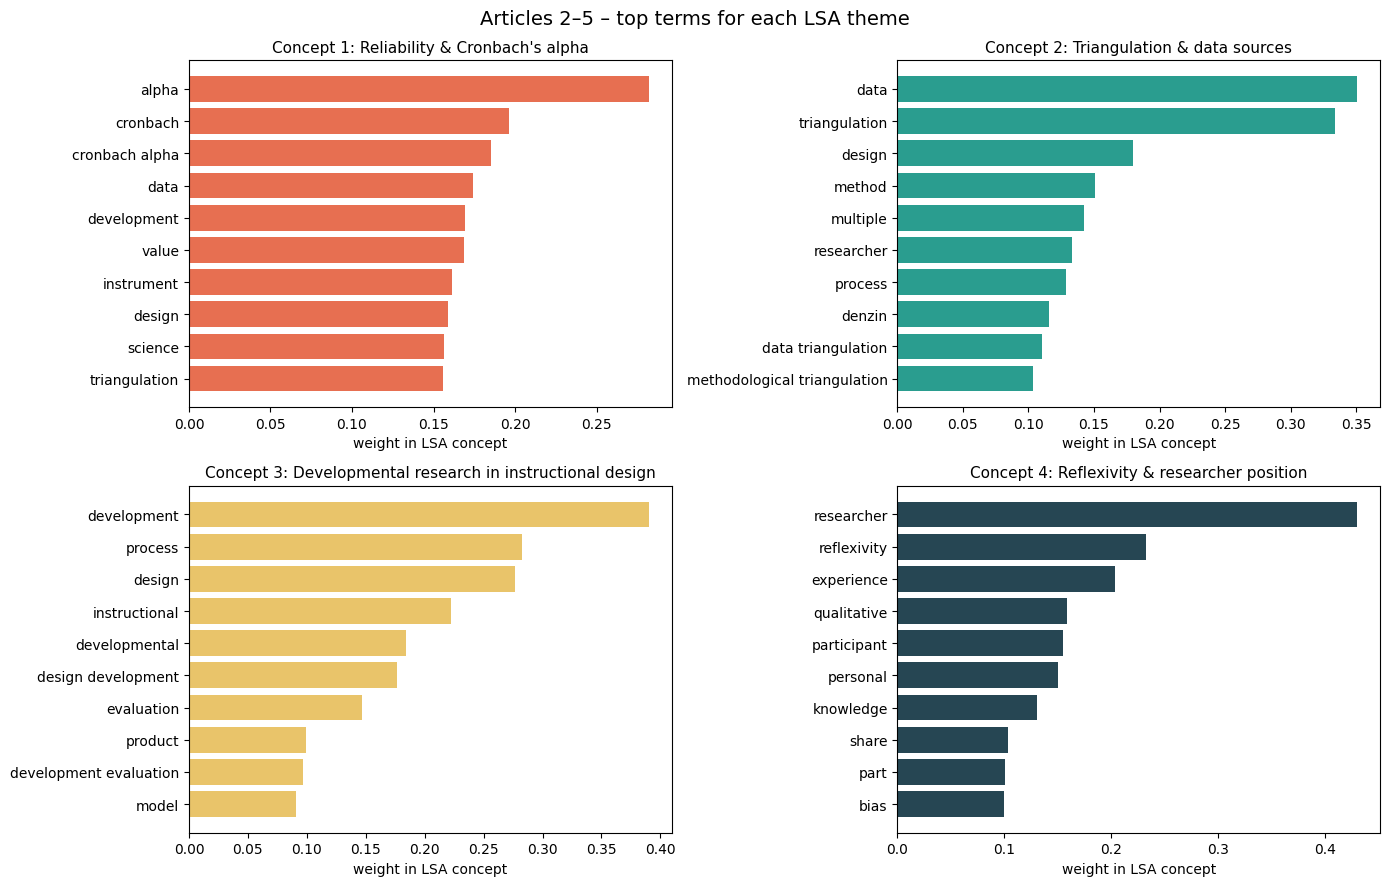

In [52]:
palette = ['#e76f51', '#2a9d8f', '#e9c46a', '#264653']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for c, ax in enumerate(axes.flat):
    words, weights = zip(*theme_terms[c])
    ax.barh(words[::-1], weights[::-1], color=palette[c])
    ax.set_title(f"Concept {c + 1}: {theme_names[c]}", fontsize=11)
    ax.set_xlabel("weight in LSA concept")
plt.suptitle("Articles 2–5 – top terms for each LSA theme", fontsize=14)
plt.tight_layout()
plt.show()

### Visualisation 2 – Which article drives which theme?


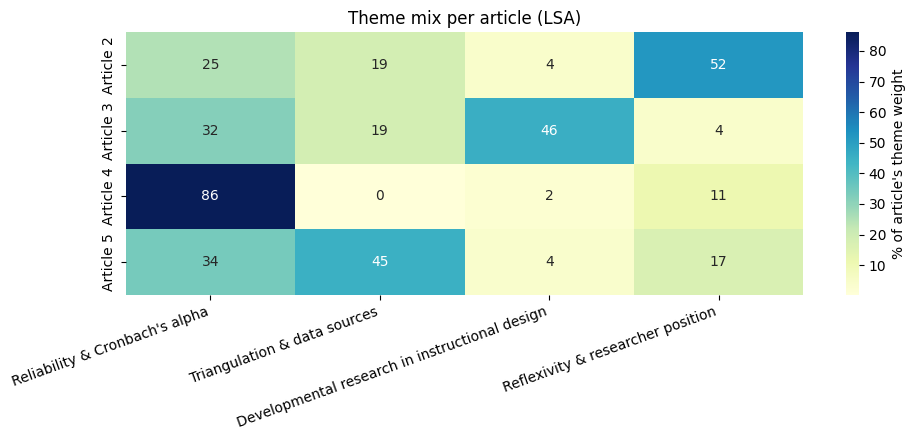

In [53]:
topic_df = pd.DataFrame(np.clip(sentence_topic, 0, None), columns=[theme_names[c] for c in range(n_themes)])
topic_df['article'] = [f"Article {a}" for a in agg_article]
article_topic = topic_df.groupby('article').mean()
article_topic_share = article_topic.div(article_topic.sum(axis=1), axis=0) * 100

plt.figure(figsize=(10, 4.5))
sns.heatmap(article_topic_share, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': '% of article\'s theme weight'})
plt.title("Theme mix per article (LSA)")
plt.xticks(rotation=20, ha='right')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Visualisation 3 – Word cloud per theme

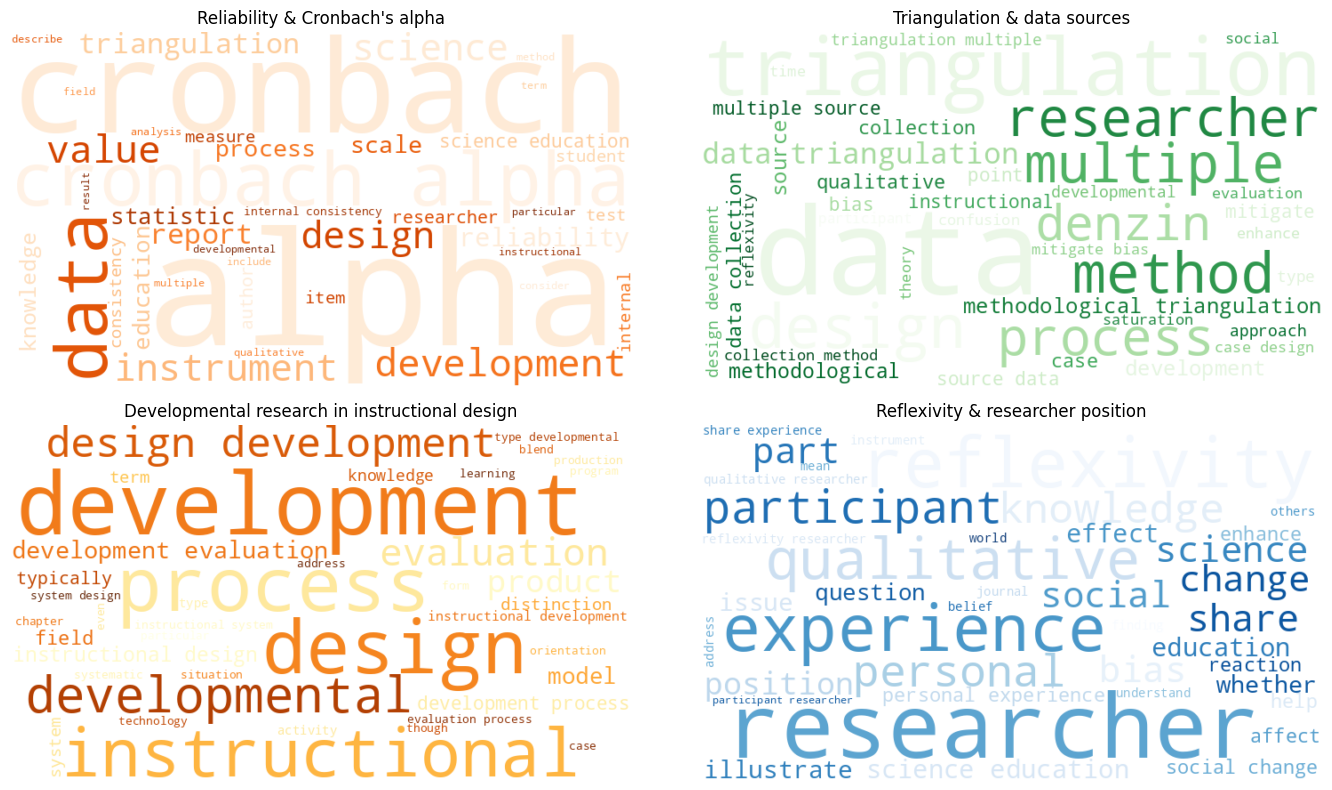

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
colormaps = ['Oranges', 'Greens', 'YlOrBr', 'Blues']
for c, ax in enumerate(axes.flat):
    weights = {lsa_terms[i]: components[c][i] for i in components[c].argsort()[::-1][:40] if components[c][i] > 0}
    cloud = WordCloud(width=700, height=400, background_color='white', colormap=colormaps[c],
                      random_state=42).generate_from_frequencies(weights)
    ax.imshow(cloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(theme_names[c], fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

LSA reduces 548 sentences to 12, about 3% of the text, and groups them in four themes. Reliability and Cronbach's alpha comes from article 4, triangulation from article 5, developmental research in instructional design from article 3, and reflexivity and researcher position from article 2. The heatmap shows one dominant theme per article with some overlap. Article 5, for example, also touches on reliability and bias. The shared thread across the corpus is research quality, meaning reliability, validity and rigour. The reliability column runs higher for every article because the first LSA concept also absorbs vocabulary common to the whole corpus.


### Question 4

## 4.1 Latent Dirichlet Allocation (LDA)

LDA treats each document as a mixture of topics and each topic as a probability distribution over words (Blei, Ng and Jordan, 2003). Five articles give LDA too few documents, so the cell splits each article into passages of five sentences, 127 documents in total. The gensim dictionary then drops words in fewer than 3 passages or in more than 50% of them.

In [55]:
academic_words = {'research', 'study', 'use', 'one', 'may', 'also', 'would', 'could', 'however', 'article',
                  'paper', 'two', 'many', 'well', 'make', 'way', 'different', 'example', 'first', 'within'}

passage_size = 5
texts, passage_article, passage_text = [], [], []
for _, row in articles.iterrows():
    for start in range(0, len(row['sentence_tokens']), passage_size):
        words = [w for s in row['sentence_tokens'][start:start + passage_size] for w in s if w not in academic_words]
        if len(words) >= 20:                       # skip tiny leftover passages at the end of an article
            texts.append(words)
            passage_article.append(row['article_id'])
            passage_text.append(' '.join(row['sentences'][start:start + passage_size]))

# Create a dictionary representation of the documents (as in the textbook)
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=3, no_above=0.5)

# Convert to a bag-of-words representation of the corpus
corpus_bow = [dictionary.doc2bow(text) for text in texts]

print(f"Passages (documents): {len(texts)}")
print("Passages per article:", pd.Series(passage_article).value_counts().sort_index().to_dict())
print(f"Vocabulary after filtering: {len(dictionary)} words")

Passages (documents): 127
Passages per article: {1: 16, 2: 12, 3: 31, 4: 36, 5: 32}
Vocabulary after filtering: 652 words


The number of topics is the hardest LDA setting (Cuantum Technologies, 2024, section 7.2.5). The next cell trains one model for each n from 2 to 10 and scores each model with C_v topic coherence. Higher scores mean better topics.

n =  2  coherence C_v = 0.5528
n =  3  coherence C_v = 0.5603
n =  4  coherence C_v = 0.5292
n =  5  coherence C_v = 0.5675
n =  6  coherence C_v = 0.5289
n =  7  coherence C_v = 0.5040
n =  8  coherence C_v = 0.5088
n =  9  coherence C_v = 0.5261
n = 10  coherence C_v = 0.5133


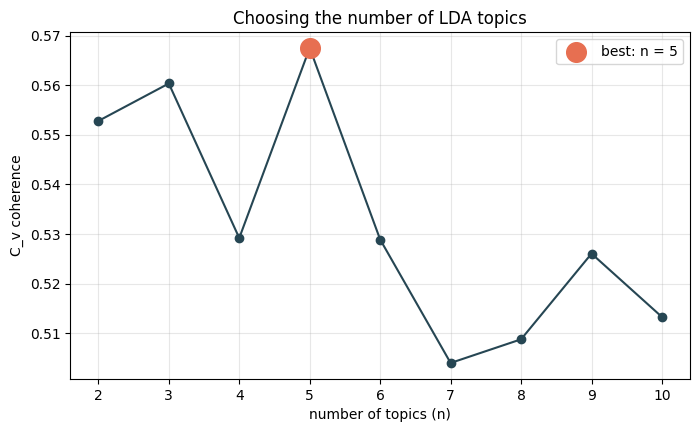

Number of topics chosen: 5


In [56]:
coherence_scores = {}
for n in range(2, 11):
    model = LdaModel(corpus=corpus_bow, id2word=dictionary, num_topics=n,
                     random_state=42, passes=20, alpha='auto', eta='auto')
    coherence_scores[n] = CoherenceModel(model=model, texts=texts, dictionary=dictionary,
                                         coherence='c_v').get_coherence()
    print(f"n = {n:2d}  coherence C_v = {coherence_scores[n]:.4f}")

best_n = max(coherence_scores, key=coherence_scores.get)

plt.figure(figsize=(8, 4.5))
plt.plot(list(coherence_scores), list(coherence_scores.values()), 'o-', color='#264653')
plt.scatter([best_n], [coherence_scores[best_n]], s=200, color='#e76f51', zorder=3, label=f'best: n = {best_n}')
plt.xlabel("number of topics (n)")
plt.ylabel("C_v coherence")
plt.title("Choosing the number of LDA topics")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("Number of topics chosen:", best_n)

### Training the final LDA model
* `passes=20`: 20 full passes over this small corpus so the model settles properly.
* `alpha='auto'` and `eta='auto'`: gensim learns the document-topic and topic-word priors from the data instead of using fixed values.
* `random_state=42`: the same topics every time the notebook runs.

In [57]:
n_topics = best_n
lda_model = LdaModel(corpus=corpus_bow, id2word=dictionary, num_topics=n_topics,
                     random_state=42, passes=20, alpha='auto', eta='auto')

coherence = CoherenceModel(model=lda_model, texts=texts, dictionary=dictionary, coherence='c_v').get_coherence()
print(f"Final model: {n_topics} topics, C_v coherence = {coherence:.4f}\n")

print("Topics:")
for topic_id, words in lda_model.print_topics(num_words=10):
    print(f"Topic {topic_id + 1}: {words}\n")

Final model: 5 topics, C_v coherence = 0.5675

Topics:
Topic 1: 0.039*"design" + 0.034*"development" + 0.023*"process" + 0.018*"instructional" + 0.018*"developmental" + 0.016*"method" + 0.013*"data" + 0.011*"type" + 0.011*"evaluation" + 0.010*"knowledge"

Topic 2: 0.038*"alpha" + 0.032*"instrument" + 0.026*"science" + 0.024*"report" + 0.022*"cronbach" + 0.020*"education" + 0.018*"statistic" + 0.018*"test" + 0.015*"measure" + 0.012*"reliability"

Topic 3: 0.072*"triangulation" + 0.054*"data" + 0.027*"multiple" + 0.024*"denzin" + 0.019*"source" + 0.019*"method" + 0.017*"qualitative" + 0.015*"methodological" + 0.012*"concept" + 0.010*"interpretation"

Topic 4: 0.049*"alpha" + 0.036*"value" + 0.026*"cronbach" + 0.025*"reliability" + 0.024*"scale" + 0.021*"internal" + 0.020*"item" + 0.019*"consistency" + 0.018*"instrument" + 0.018*"report"

Topic 5: 0.052*"researcher" + 0.022*"qualitative" + 0.018*"data" + 0.018*"reflexivity" + 0.017*"experience" + 0.016*"social" + 0.015*"method" + 0.012*"c

Topic word lists. Each topic is labelled from its top words:

In [58]:
theme_signals = {
    "Reliability & Cronbach's alpha": ['alpha', 'cronbach', 'reliability', 'statistic', 'internal', 'consistency', 'value'],
    "Measurement instruments & items": ['instrument', 'item', 'scale', 'measure', 'test', 'construct', 'score'],
    "Triangulation & qualitative data": ['triangulation', 'data', 'denzin', 'multiple', 'source', 'bias', 'saturation'],
    "Reflexivity & researcher position": ['reflexivity', 'position', 'personal', 'experience', 'insider', 'participant', 'share'],
    "Developmental research & instructional design": ['developmental', 'development', 'instructional', 'design', 'evaluation', 'process', 'product'],
    "Research paradigms & philosophy of knowledge": ['reality', 'knowledge', 'paradigm', 'pragmatism', 'purist', 'epistemological', 'belief', 'philosophical', 'social'],
    "Mixed methods research": ['mixed', 'quantitative', 'qualitative', 'method', 'combine', 'approach'],
}

topic_words = {t: lda_model.show_topic(t, topn=15) for t in range(n_topics)}
theme_scores = {(t, theme): sum(p for w, p in topic_words[t] if w in signals)
          for t in range(n_topics) for theme, signals in theme_signals.items()}

topic_names, used = {}, set()
for (t, theme), s in sorted(theme_scores.items(), key=lambda x: -x[1]):      # strongest matches first, one theme per topic
    if t not in topic_names and theme not in used and s > 0.03:
        topic_names[t] = theme
        used.add(theme)
for t in range(n_topics):
    topic_names.setdefault(t, ' / '.join(w for w, _ in topic_words[t][:3]))

topic_table = pd.DataFrame({
    f"T{t + 1}: {topic_names[t]}": [f"{w} ({p:.3f})" for w, p in lda_model.show_topic(t, topn=10)]
    for t in range(n_topics)
})
topic_table.index = range(1, 11)
topic_table

,T1: Developmental research & instructional design,T2: Measurement instruments & items,T3: Triangulation & qualitative data,T4: Reliability & Cronbach's alpha,T5: Reflexivity & researcher position
1,design (0.039),alpha (0.038),triangulation (0.072),alpha (0.049),researcher (0.052)
2,development (0.034),instrument (0.032),data (0.054),value (0.036),qualitative (0.022)
3,process (0.023),science (0.026),multiple (0.027),cronbach (0.026),data (0.018)
4,instructional (0.018),report (0.024),denzin (0.024),reliability (0.025),reflexivity (0.018)
5,developmental (0.018),cronbach (0.022),source (0.019),scale (0.024),experience (0.017)
6,method (0.016),education (0.020),method (0.019),internal (0.021),social (0.016)
7,data (0.013),statistic (0.018),qualitative (0.017),item (0.020),method (0.015)
8,type (0.011),test (0.018),methodological (0.015),consistency (0.019),change (0.012)
9,evaluation (0.011),measure (0.015),concept (0.012),instrument (0.018),position (0.011)
10,knowledge (0.010),reliability (0.012),interpretation (0.010),report (0.018),personal (0.010)


### Visualisation 1 – Top words and their probabilities in each topic

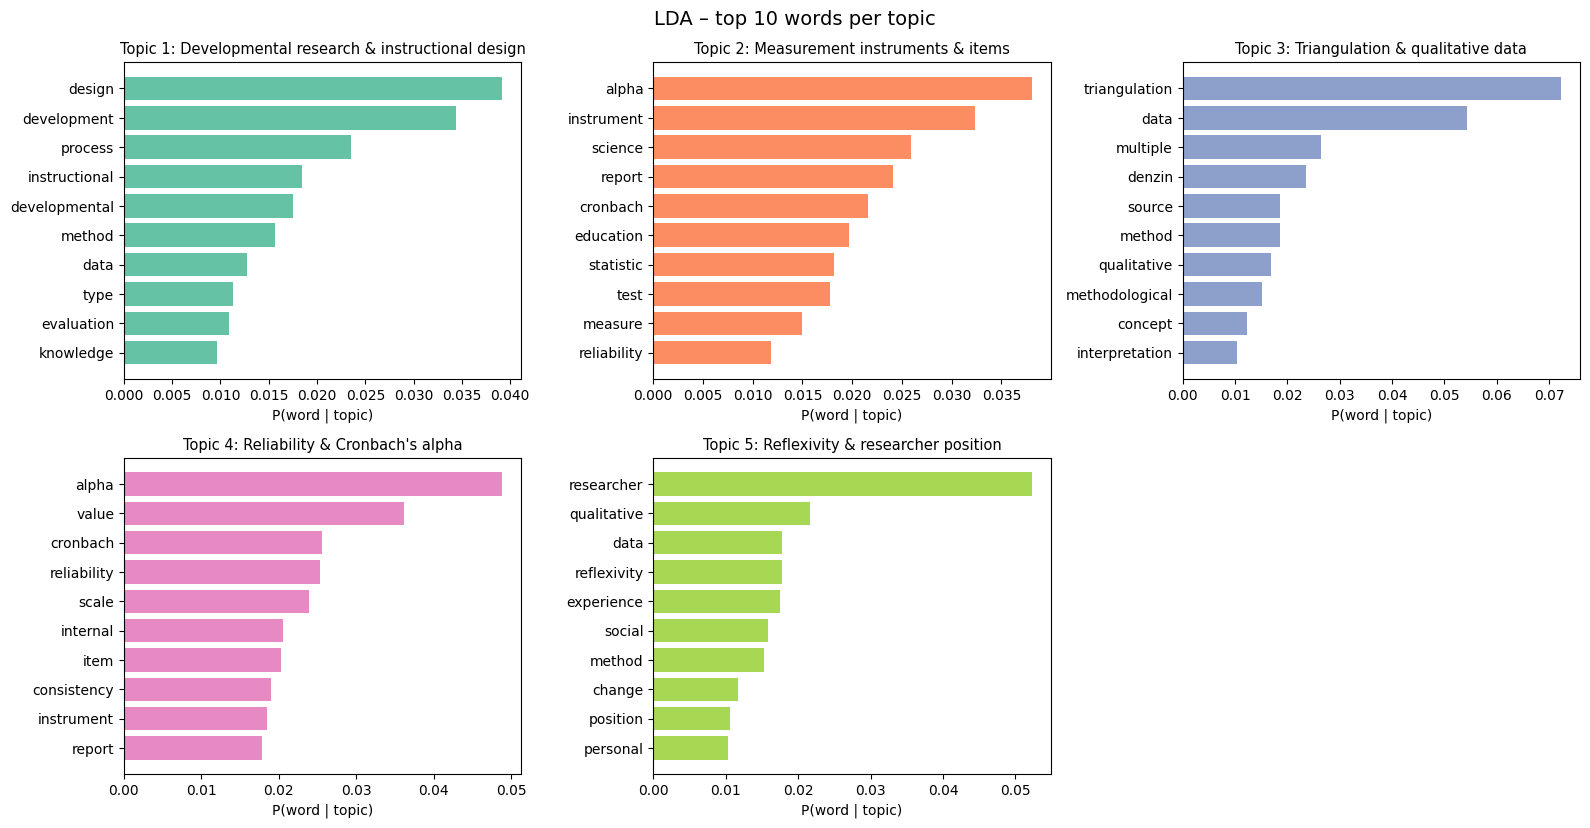

In [59]:
palette = sns.color_palette('Set2', n_topics)
cols = 3
rows = int(np.ceil(n_topics / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, 4.2 * rows))
for t, ax in enumerate(axes.flat):
    if t >= n_topics:
        ax.axis('off')
        continue
    words, probs = zip(*lda_model.show_topic(t, topn=10))
    ax.barh(words[::-1], probs[::-1], color=palette[t])
    ax.set_title(f"Topic {t + 1}: {topic_names[t]}", fontsize=10.5)
    ax.set_xlabel("P(word | topic)")
plt.suptitle("LDA – top 10 words per topic", fontsize=14)
plt.tight_layout()
plt.show()

### Visualisation 2 – Word clouds per topic

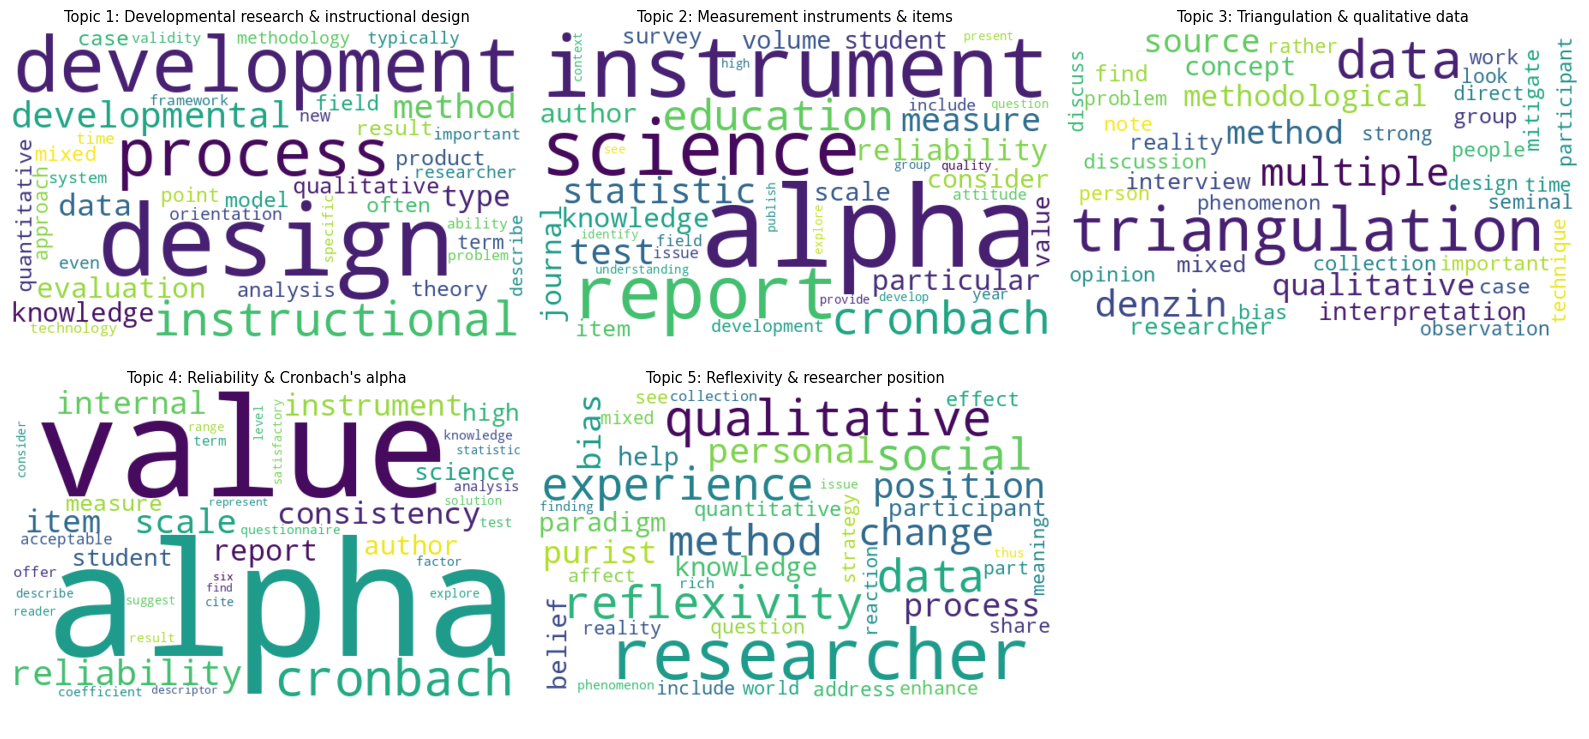

In [60]:
fig, axes = plt.subplots(rows, cols, figsize=(16, 3.8 * rows))
for t, ax in enumerate(axes.flat):
    if t >= n_topics:
        ax.axis('off')
        continue
    cloud = WordCloud(width=600, height=360, background_color='white', colormap='viridis',
                      random_state=42).generate_from_frequencies(dict(lda_model.show_topic(t, topn=40)))
    ax.imshow(cloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f"Topic {t + 1}: {topic_names[t]}", fontsize=10.5)
plt.tight_layout()
plt.show()

Topic distribution across the corpus, per article, and through the passages:

In [61]:
doc_topics = np.array([[p for _, p in lda_model.get_document_topics(bow, minimum_probability=0)]
                       for bow in corpus_bow])
doc_topic_df = pd.DataFrame(doc_topics, columns=[f"T{t + 1}" for t in range(n_topics)])
doc_topic_df['article'] = [f"Article {a}" for a in passage_article]
doc_topic_df['dominant_topic'] = doc_topics.argmax(axis=1) + 1

# 1. overall prevalence, weighted by passage length
lengths = np.array([len(t) for t in texts])
prevalence = (doc_topics * lengths[:, None]).sum(axis=0) / lengths.sum() * 100
prevalence_df = pd.DataFrame({'topic': [f"T{t + 1}: {topic_names[t]}" for t in range(n_topics)],
                              'share of corpus (%)': prevalence.round(1),
                              'passages where dominant': np.bincount(doc_topics.argmax(axis=1), minlength=n_topics)})
prevalence_df.sort_values('share of corpus (%)', ascending=False)

,topic,share of corpus (%),passages where dominant
0,T1: Developmental research & instructional design,29.1,46
4,T5: Reflexivity & researcher position,25.3,29
3,T4: Reliability & Cronbach's alpha,17.4,18
1,T2: Measurement instruments & items,16.0,18
2,T3: Triangulation & qualitative data,12.1,16


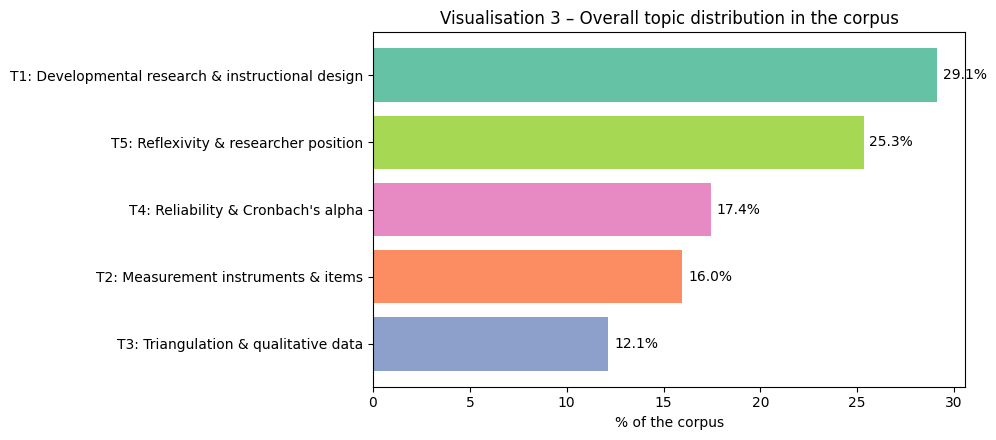

In [62]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = np.argsort(prevalence)
ax.barh([f"T{t + 1}: {topic_names[t]}" for t in order], prevalence[order], color=[palette[t] for t in order])
for i, t in enumerate(order):
    ax.text(prevalence[t] + 0.3, i, f"{prevalence[t]:.1f}%", va='center')
ax.set_xlabel("% of the corpus")
ax.set_title("Visualisation 3 – Overall topic distribution in the corpus")
plt.tight_layout()
plt.show()

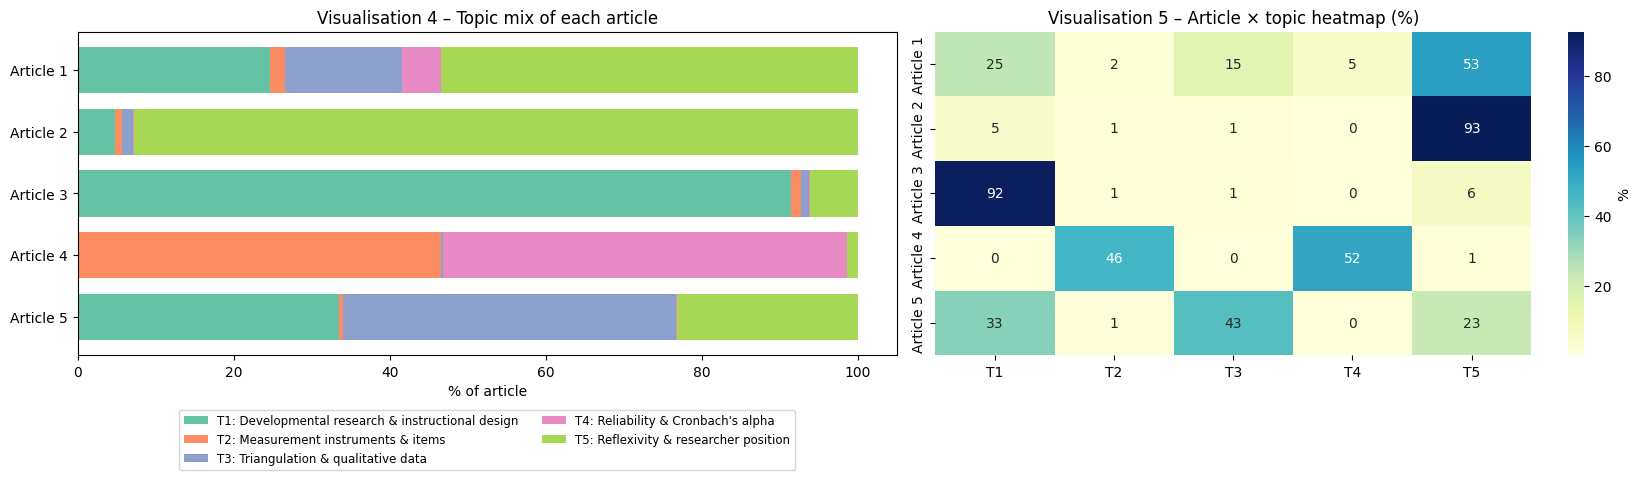

In [63]:
article_mix = doc_topic_df.groupby('article')[[f"T{t + 1}" for t in range(n_topics)]].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={'width_ratios': [1.1, 1]})
article_mix.plot(kind='barh', stacked=True, ax=axes[0], color=palette, width=0.75)
axes[0].invert_yaxis()
axes[0].set_xlabel("% of article")
axes[0].set_title("Visualisation 4 – Topic mix of each article")
axes[0].legend([f"T{t + 1}: {topic_names[t]}" for t in range(n_topics)], bbox_to_anchor=(0.5, -0.15),
               loc='upper center', ncol=2, fontsize=8.5)
axes[0].set_ylabel('')

sns.heatmap(article_mix, annot=True, fmt='.0f', cmap='YlGnBu', ax=axes[1], cbar_kws={'label': '%'})
axes[1].set_title("Visualisation 5 – Article × topic heatmap (%)")
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

### Visualisation 6 – Topic distribution through every passage


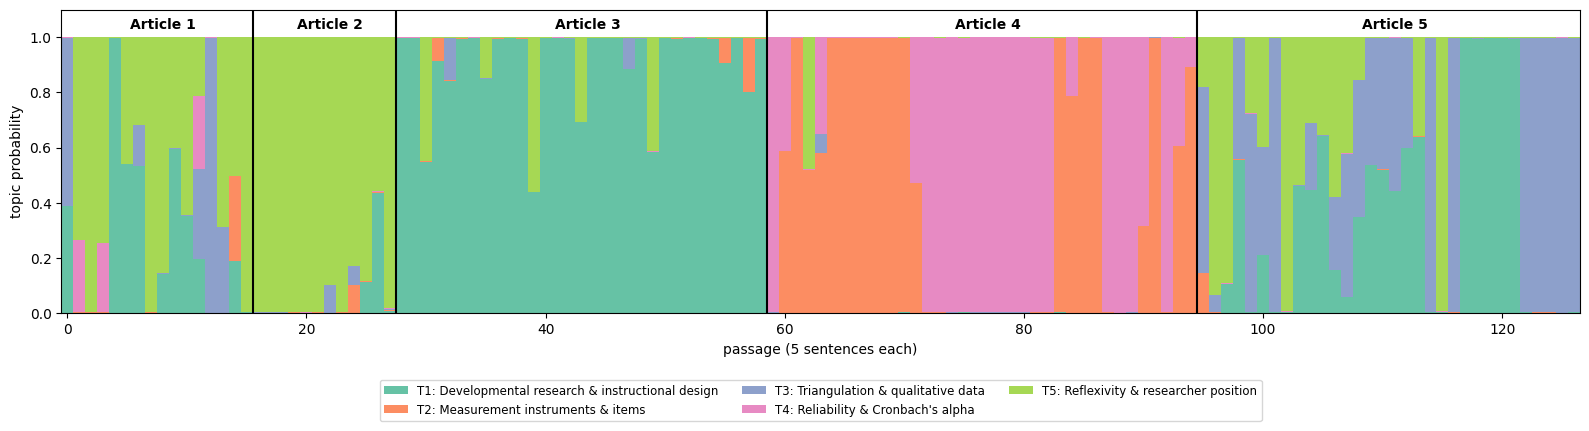

In [64]:
fig, ax = plt.subplots(figsize=(16, 4.5))
bottom = np.zeros(len(doc_topics))
x = np.arange(len(doc_topics))
for t in range(n_topics):
    ax.bar(x, doc_topics[:, t], bottom=bottom, color=palette[t], width=1.0, label=f"T{t + 1}: {topic_names[t]}")
    bottom += doc_topics[:, t]
boundaries = np.cumsum(pd.Series(passage_article).value_counts().sort_index().values)
for b in boundaries[:-1]:
    ax.axvline(b - 0.5, color='black', linewidth=1.5)
starts = np.concatenate([[0], boundaries[:-1]])
for a, (s, e) in enumerate(zip(starts, boundaries), 1):
    ax.text((s + e) / 2, 1.03, f"Article {a}", ha='center', fontsize=10, fontweight='bold')
ax.set_xlim(-0.5, len(doc_topics) - 0.5)
ax.set_ylim(0, 1.1)
ax.set_xlabel("passage (5 sentences each)")
ax.set_ylabel("topic probability")
ax.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center', ncol=3, fontsize=8.5)
plt.tight_layout()
plt.show()

### Interpretation

Coherence peaks at n = 5 with C_v = 0.5675. Developmental research and instructional design covers 29.1% of the corpus, reflexivity and researcher position 25.3%, reliability and Cronbach's alpha 17.4%, measurement instruments and items 16.0% and triangulation 12.1%.

One topic dominates most articles. Article 2 holds 93% reflexivity (T5) and article 3 holds 92% developmental research (T1). Article 4 splits between Cronbach's alpha (T4, 52%) and the measurement instruments behind the statistic (T2, 46%). Article 5 mixes triangulation (T3, 43%) with developmental research (T1, 33%) and reflexivity (T5, 23%). Article 1 on mixed methods leans on reflexivity (T5, 53%) with developmental research at 25%, since the paper discusses the researcher and the research design together. LDA recovers the subject of each paper without any label.

## 4.2 Interactive Intertopic Distance Map
pyLDAvis draws each topic as a circle (Sievert and Shirley, 2014). Circle size shows the share of the corpus, and the distance between circles shows how different the word distributions are. The right panel lists the most salient words. Click a circle to see the most relevant words for the topic, and move the λ slider to about 0.6 to favour words specific to the topic. The code sets mds='mmds' because the default PCoA option fails with recent numpy and scipy versions, and sort_topics=False keeps the topic numbers from 4.1.

In [65]:
pyLDAvis.enable_notebook()
# mds='mmds' (metric multidimensional scaling) instead of the default 'pcoa': with recent numpy/scipy the
# default PCoA returns complex numbers and save_html fails with "complex128 is not JSON serializable"
vis = pyLDAvis.gensim_models.prepare(lda_model, corpus_bow, dictionary, mds='mmds', sort_topics=False)
pyLDAvis.save_html(vis, 'lda_intertopic_distance_map.html')
print("Saved: lda_intertopic_distance_map.html (open it in any browser)")
vis

Saved: lda_intertopic_distance_map.html (open it in any browser)


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.190418 -0.024401       1        1  29.409270
1      0.009926  0.183363       2        1  16.621267
2     -0.137670 -0.157333       3        1  12.585790
3     -0.124419  0.194115       4        1  18.089014
4      0.061745 -0.195744       5        1  23.294660, topic_info=              Term        Freq       Total Category  logprob  loglift
315  triangulation   65.000000   65.000000  Default  30.0000  30.0000
255          alpha  100.000000  100.000000  Default  29.0000  29.0000
81            data   99.000000   99.000000  Default  28.0000  28.0000
70      researcher  101.000000  101.000000  Default  27.0000  27.0000
8           design   85.000000   85.000000  Default  26.0000  26.0000
..             ...         ...         ...      ...      ...      ...
31         process   13.833564   62.373644   Topic5  -4.7097  -0.0491
35    quantitative   10.536131   30.311096   Topic5  -4.9820   0.4002
335      knowledge   12.393065   52.828826   Topic5  -4.8197   0.0070
100        reality    8.647656   17.402328   Topic5  -5.1795   0.7576
419        enhance    7.883591   13.856534   Topic5  -5.2720   0.8930

[303 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
461       1  0.760665     ability
461       2  0.169037     ability
560       2  0.185244  acceptable
560       4  0.802726  acceptable
636       2  0.893448        acid
...     ...       ...         ...
449       1  0.158753        year
449       2  0.555636        year
449       3  0.079377        year
449       4  0.079377        year
449       5  0.079377        year

[542 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])

In [66]:
info = vis.topic_info

overall_salient = info[info['Category'] == 'Default'].head(15)[['Term', 'Freq', 'Total']]
print("Most salient terms in the whole corpus:")
print(', '.join(overall_salient['Term']))

def most_relevant(topic_number, lam=0.6, n=10):
    t = info[info['Category'] == f"Topic{topic_number}"].copy()
    t['relevance'] = lam * t['logprob'] + (1 - lam) * t['loglift']
    return t.sort_values('relevance', ascending=False)['Term'].head(n).tolist()

salient_table = pd.DataFrame({f"T{t + 1}: {topic_names[t]}": most_relevant(t + 1) for t in range(n_topics)})
salient_table.index = range(1, 11)
print("\nMost relevant words per topic at λ = 0.6:")
salient_table

Most salient terms in the whole corpus:
triangulation, alpha, data, researcher, design, cronbach, instrument, development, value, scale, multiple, report, instructional, denzin, science

Most relevant words per topic at λ = 0.6:


,T1: Developmental research & instructional design,T2: Measurement instruments & items,T3: Triangulation & qualitative data,T4: Reliability & Cronbach's alpha,T5: Reflexivity & researcher position
1,design,instrument,triangulation,alpha,researcher
2,development,alpha,data,value,reflexivity
3,process,science,denzin,internal,experience
4,instructional,education,multiple,scale,social
5,developmental,report,source,consistency,qualitative
6,evaluation,statistic,methodological,reliability,change
7,type,test,method,cronbach,personal
8,method,cronbach,interpretation,item,position
9,model,measure,interview,author,purist
10,product,volume,seminal,acceptable,data


In [67]:
try:
    from google.colab import files
    files.download('lda_intertopic_distance_map.html')
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Interpretation

All five circles sit apart with no overlap, so the topics differ. The closest pair, T2 for measurement instruments and T4 for Cronbach's alpha, both come from article 4 and sit together at the top of the map. The two qualitative rigour topics, T3 for triangulation and T5 for reflexivity, sit close together at the bottom. The most salient words, triangulation, alpha, data, researcher, design, cronbach, instrument, development, value and scale, name almost every topic. The next cell downloads the map as an HTML file you open in any browser.

---
# End of the project

All four questions run from one set of imports and one upload. The Files panel in Colab holds the files the notebook creates. The web app for Question 2.3 uses models/best_model.pickle, app.py and templates/index.html. The interactive topic map for Question 4.2 sits in lda_intertopic_distance_map.html, which opens in any browser.